# Predicción del precio de viviendas mediante modelos de regresión

## Objetivo

El objetivo de este proyecto es analizar el conjunto de datos Boston Housing y estudiar el comportamiento de distintos modelos de regresión para predecir el valor medio de las viviendas.

Además del rendimiento predictivo, se analizan las características del conjunto de datos, el impacto del preprocesamiento y el efecto de distintas técnicas de regularización y optimización sobre el desempeño del modelo.

## Preguntas de investigación

- ¿Qué variables presentan una mayor influencia sobre el precio de las viviendas?
- ¿Un modelo de regresión lineal resulta adecuado para este problema?
- ¿Qué diferencias existen entre la solución analítica y los distintos algoritmos de descenso por gradiente?
- ¿Cómo afectan las técnicas de regularización (Ridge, Lasso y Elastic Net) al rendimiento y a la selección de variables?
- ¿Qué modelo ofrece el mejor equilibrio entre capacidad predictiva e interpretabilidad?

## Modelos evaluados

- Linear Regression
- Batch Gradient Descent
- Stochastic Gradient Descent
- Mini-Batch Gradient Descent
- Ridge
- Lasso
- Elastic Net

#### Librerías iniciales

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Estructura del dataset original

In [ ]:
data_orig = pd.read_csv("house-prices-tp.csv")
print(f" Dataset de {data_orig.shape[0]:,} Registros con {data_orig.shape[1]} características")

 Dataset de 556 Registros con 14 características


In [ ]:
print(f"\nPrimeras filas:")
data_orig.head()


Primeras filas:


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.07151,0.0,4.49,0.0,0.449,6.121,56.8,3.7476,3.0,247.0,18.5,395.15,8.44,22.2
1,0.08265,0.0,13.92,0.0,0.437,6.127,18.4,5.5027,4.0,289.0,16.0,396.90,8.58,23.9
2,0.12816,12.5,6.07,0.0,0.409,5.885,33.0,6.4980,4.0,345.0,18.9,396.90,8.79,20.9
3,0.08873,21.0,5.64,0.0,0.439,5.963,45.7,6.8147,4.0,243.0,16.8,395.56,13.45,19.7
4,0.11432,0.0,8.56,0.0,0.520,6.781,71.3,2.8561,5.0,384.0,20.9,395.58,7.67,26.5


In [ ]:
print(f"\nTipos de datos:")
data_orig.dtypes


Tipos de datos:


,0
CRIM,float64
ZN,float64
INDUS,float64
CHAS,float64
NOX,float64
RM,float64
AGE,float64
DIS,float64
RAD,float64
TAX,float64


#### Valores nulos o duplicados

In [ ]:
print(f"Valores nulos:")
print(data_orig.isnull().sum().sort_values(ascending=False)) # Nulos por variable, en forma desc.

print(f"\nPorcentaje de nulos por columna:")
print((data_orig.isna().mean()*100).round(2).sort_values(ascending=False)) # En porcentajes

print(f"\nCantidad de registros totalmente nulos:")
print(len(data_orig[data_orig.isna().all(axis=1)])) # Fila a eliminar

print("\nFilas sin MEDV:", data_orig['MEDV'].isnull().sum()) # Fila a eliminar

Valores nulos:
PTRATIO    28
RAD        28
NOX        24
AGE        24
CHAS       23
CRIM       23
LSTAT      22
B          22
ZN         22
RM         21
MEDV       21
TAX        18
INDUS      15
DIS        15
dtype: int64

Porcentaje de nulos por columna:
PTRATIO    5.04
RAD        5.04
NOX        4.32
AGE        4.32
CHAS       4.14
CRIM       4.14
LSTAT      3.96
B          3.96
ZN         3.96
RM         3.78
MEDV       3.78
TAX        3.24
INDUS      2.70
DIS        2.70
dtype: float64

Cantidad de registros totalmente nulos:
1

Filas sin MEDV: 21


In [ ]:
# Cantidad de filas completamente duplicadas
print(f"Filas con valores duplicados: {data_orig.duplicated().sum()}")

Filas con valores duplicados: 0


#### Eliminacion de filas nulas o sin MEDV

Para el presente análisis se descartan las filas sin target (MEDV) porque no se puede evaluar ni entrenar supervisado sin etiqueta, asi como los llenos de nulos, por no aportar nada. Posteriormente, se revisa el estado del dataset post eliminación.

In [ ]:
data_orig = data_orig.dropna(subset=['MEDV'])
data_orig = data_orig.dropna(how='all')
print(f"Dataset después de eliminar nulos: {data_orig.shape[0]:,} Registros con {data_orig.shape[1]} características")

print(f"\nValores nulos después de la limpieza:")
print(data_orig.isnull().sum().sort_values(ascending=False))

print(f"\nPorcentaje de nulos por columna:")
print((data_orig.isna().mean()*100).round(2).sort_values(ascending=False))

Dataset después de eliminar nulos: 535 Registros con 14 características

Valores nulos después de la limpieza:
RAD        12
CRIM       11
AGE        11
ZN         11
CHAS        9
NOX         9
LSTAT       9
B           9
TAX         9
PTRATIO     9
RM          7
DIS         5
INDUS       4
MEDV        0
dtype: int64

Porcentaje de nulos por columna:
RAD        2.24
CRIM       2.06
AGE        2.06
ZN         2.06
CHAS       1.68
NOX        1.68
LSTAT      1.68
B          1.68
TAX        1.68
PTRATIO    1.68
RM         1.31
DIS        0.93
INDUS      0.75
MEDV       0.00
dtype: float64


#### Descripciones generales

In [ ]:
round(data_orig.describe(), 2)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,524.00,524.00,531.00,526.00,526.00,528.00,524.00,530.00,523.00,526.00,526.00,526.00,526.00,535.00
mean,4.99,12.50,11.23,0.09,0.56,6.28,67.66,3.89,9.62,409.19,18.42,350.87,12.97,22.75
std,11.94,24.29,6.92,0.28,0.12,0.75,28.57,2.21,8.67,167.88,2.20,96.82,7.51,9.49
min,0.01,0.00,0.46,0.00,0.38,3.56,2.90,1.13,1.00,187.00,12.60,0.32,1.73,5.00
25%,0.08,0.00,5.13,0.00,0.45,5.88,42.28,2.11,4.00,279.00,17.00,371.62,7.12,16.75
50%,0.29,0.00,9.69,0.00,0.54,6.20,76.50,3.32,5.00,334.00,19.00,390.94,11.46,21.20
75%,4.55,20.00,18.10,0.00,0.63,6.63,93.90,5.29,24.00,666.00,20.20,396.04,17.16,26.30
max,88.98,100.00,27.74,1.00,0.87,8.78,100.00,12.13,24.00,711.00,22.00,396.90,37.97,50.00


**Observaciones:**

**Variables con alta dispersión:**
- **CRIM** presenta un desvío estándar (11.94) más de dos veces mayor que su media (4.99), y una media muy superior a la mediana (0.29). La distribución es fuertemente asimétrica a derecha.
- **ZN** también tiene un desvío (24.29) mayor que su media (12.50); se debe revisar con más detalle su distribución.

**Variables con baja dispersión:**
- **RM** y **PTRATIO** tienen desvíos pequeños en relación a su media (alrededor del 12%), por lo que sus valores están concentrados.

**Otras variables con posibles outliers:**
- **B:** asimétrica a izquierda. El 75% de los valores supera 371, pero hay zonas con valores muy bajos (mínimo 0.32), por debajo del límite inferior de 335.
- **LSTAT** (máx. 37.97) y **DIS** (máx. 12.13) superan levemente sus límites superiores (32.2 y 10.1).
- **MEDV:** valores por encima de 40.6 son atípicos según el IQR, y el máximo de 50 corresponde a un valor de censura conocido de este dataset (precios mayores se registraron como 50).

**Variables sin outliers según el IQR pero con distribución particular:**
- **RAD** y **TAX:** el percentil 75 coincide o casi coincide con el máximo (24 y 666 vs. 711), lo que sugiere un grupo de zonas con valores muy altos separado del resto (distribución bimodal), más que outliers aislados.
- **CHAS:** binaria, con solo un 9% de zonas lindantes al río; su desvío no tiene la misma interpretación que las demás variables.

#### Visualizaciones

**Histograma de MEDV**

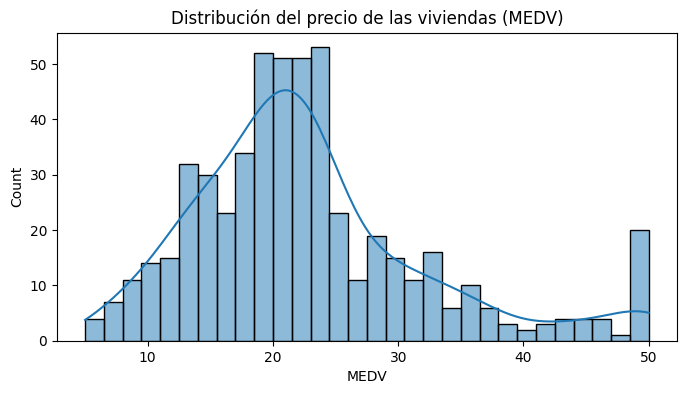

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(data_orig['MEDV'], kde=True, bins=30)
plt.title('Distribución del precio de las viviendas (MEDV)')
plt.show()

Los datos naturalmente presentan una distribucion practicamente normal. El problema es que parece haber un truncamiento en 50. Como se vio en la tabla anterior, este es el máximo valor presentado en el dataset. Una posible explicación es que que a las casas que valian más de 50 (y permitian que la distribucion sea simetrica) se les asigno un límite de 50 por defecto.

**Matriz de correlación**

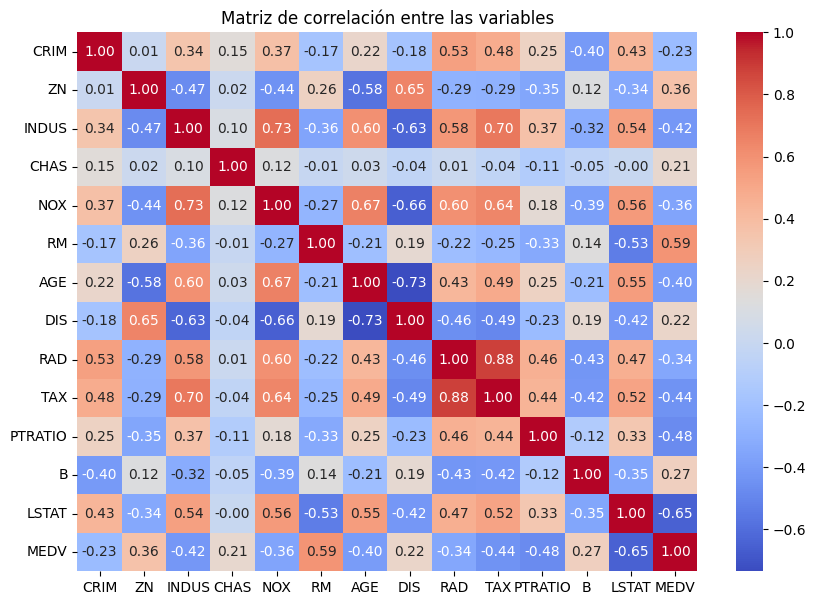

In [ ]:
plt.figure(figsize=(10, 7))
sns.heatmap(data_orig.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriz de correlación entre las variables')
plt.show()

Multicolinealidad entre predictores, mayor a 0.70:
- Alta correlacion entre RAD y TAX (r=0.88)
- Entre NOX e INDUS (r=0.73)
- Entre TAX e INDUS (r=0.70).

Relacion alta con MEDV (target):
- RM tiene una alta relacion positiva (r=0.59) y LSTAT una alta relacion negativa (r=-0.65).

Para profundizar el análisis de estas relaciones se utilizan gráficos de dispersión.

**Relaciones entre las principales variables**

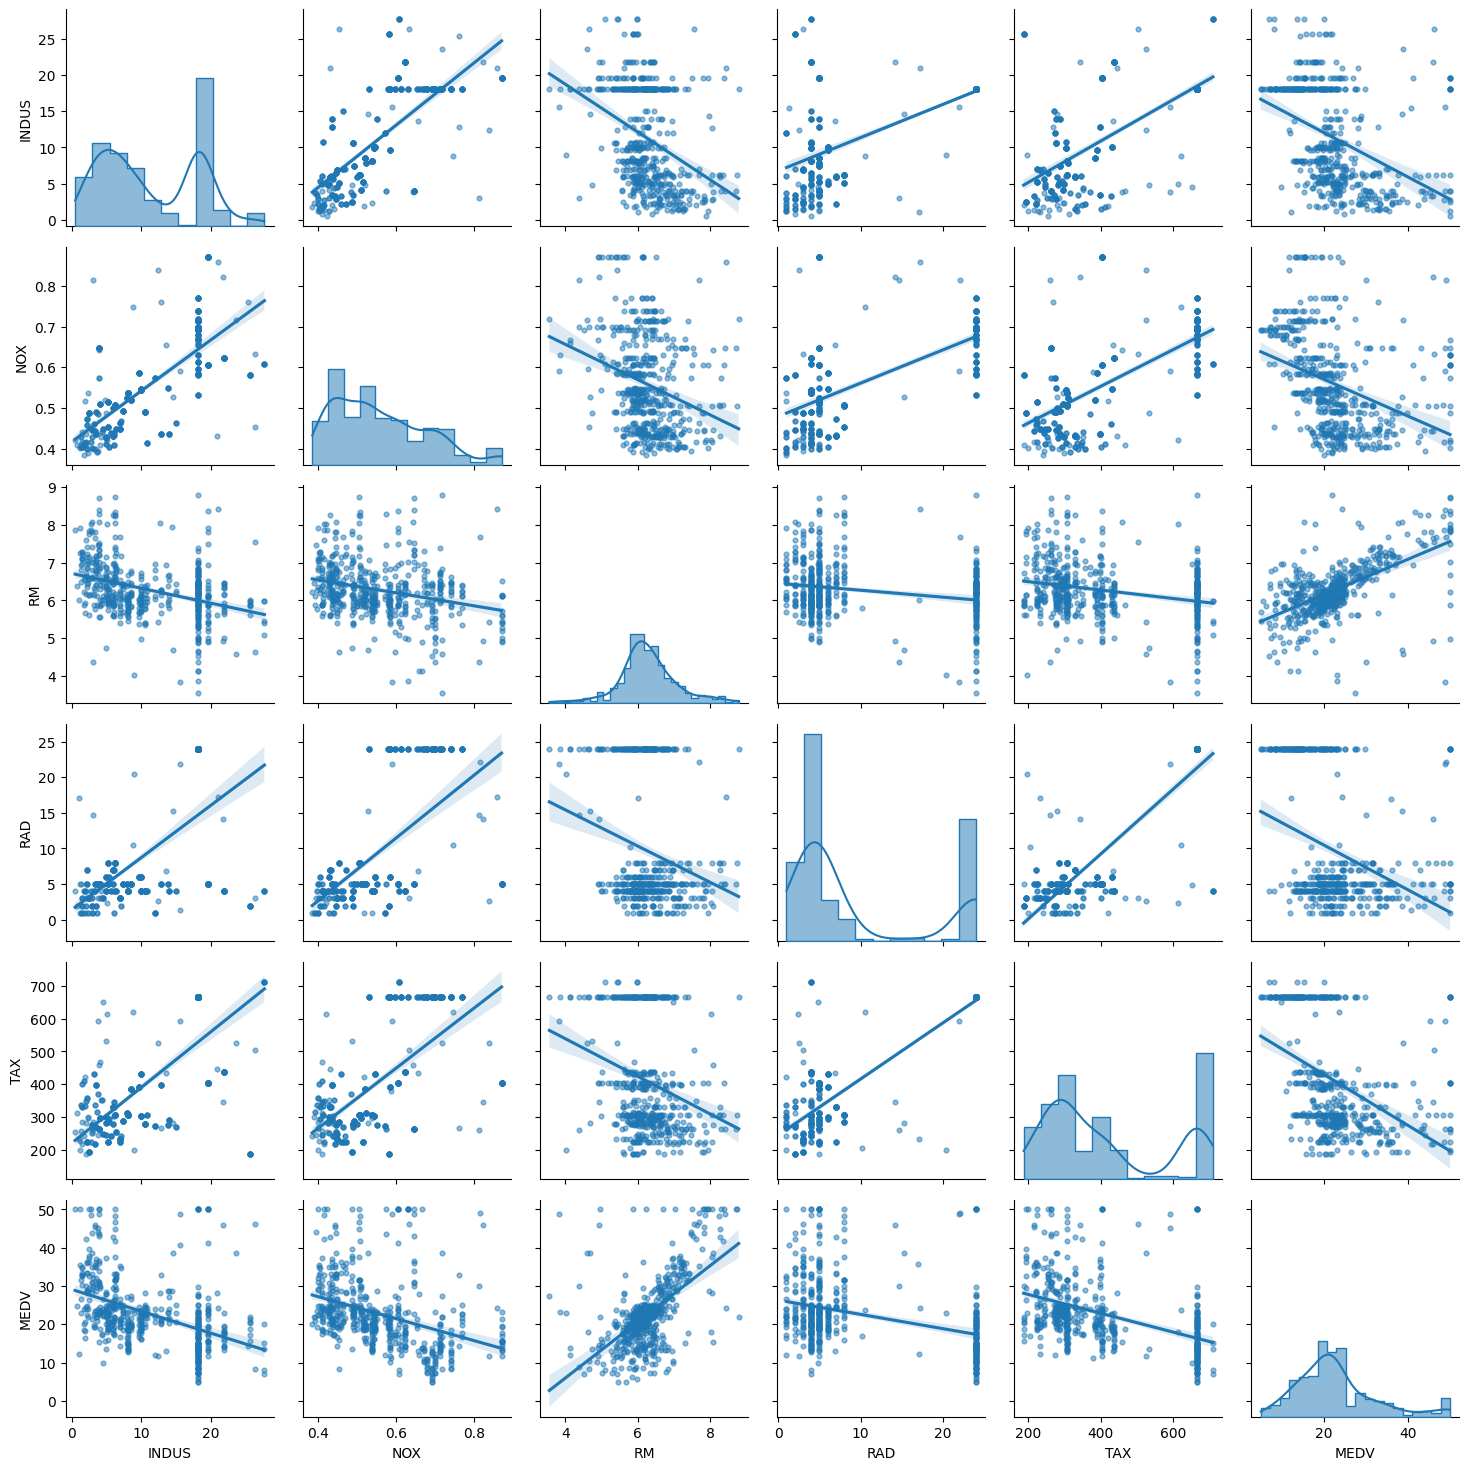

In [ ]:
g = sns.PairGrid(data_orig[['INDUS', 'NOX', 'RM', 'RAD', 'TAX', 'MEDV']])
g.map_diag(sns.histplot, kde=True, element='step')
g.map_offdiag(sns.regplot, scatter_kws={'alpha': 0.5, 's': 12})

Detalles:
- Correlación entre RAD y TAX: hay dos grupos separados ya que hay una nube entre RAD 1-8 y otra columna en RAD=24, con un vacío total entre 8 y 24. La más fuerte es la primera.
- Entre NOX e INDUS: similar al anterior pero sin separaciones tan marcadas entre grupos.
- Entre TAX e INDUS: la nube sube de forma bastante continua en todo el rango, aunque también hay una concentración vertical en INDUS alrededor de 18 (más suelo industrial, más óxidos de nitrógeno)

#### Outliers

**Boxplots**

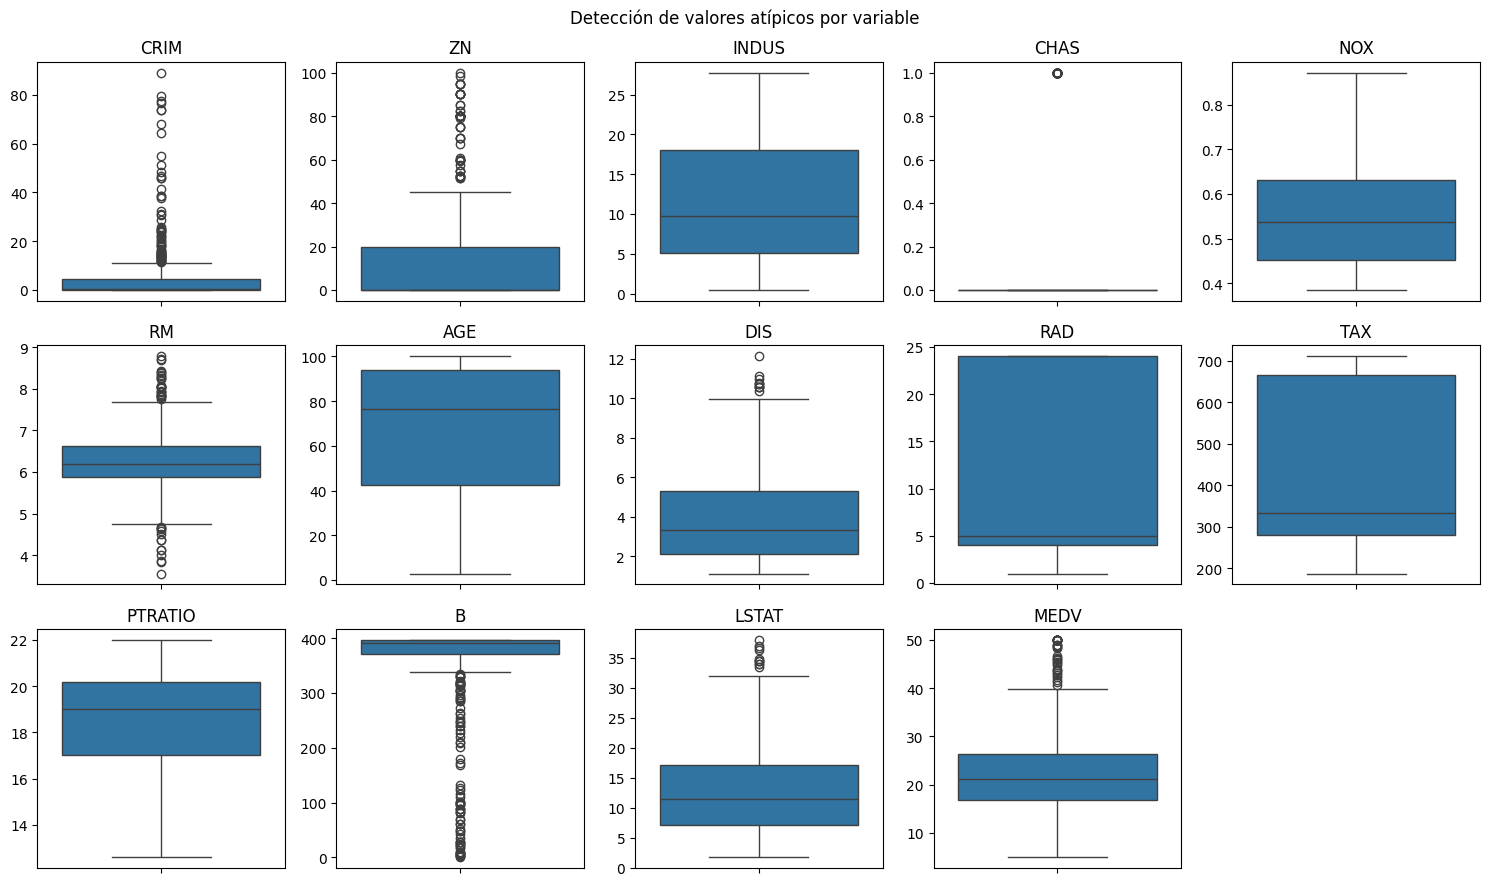

In [ ]:
colum = data_orig.columns

fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for ax, col in zip(axes.flat, colum):
    sns.boxplot(y=data_orig[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel('')

for ax in axes.flat[len(colum):]:
    ax.set_visible(False)

fig.suptitle('Detección de valores atípicos por variable')
plt.tight_layout()
plt.show()

**Variables con outliers notorios:**
- CRIM (tasa de criminalidad): valores máximos del bigote superior alrededor de 15. Los outliers pueden deberse a valores pertenecientes a zonas específicas de la ciudad. Se imputan nulos por mediana.
- ZN (proporción de terrenos residenciales zonificados de más de 25 mil pies cuadrados): mayoría de los valores en cero (o hasta 20%) y una cola larga de zonas residenciales exclusivas. Se evaluará si se imputan nulos por la mediana.
- CHAS (1 si el tramo limita con el río Charles; 0 de lo contrario): variable booleana. Lo único destacable es que la mayoría de los datos indican no limitar con el río. No se escala pero se imputarán nulos por moda.
- RM (promedio de habitaciones por vivienda): distribución con colas hacia ambos lados, lo que apunta a una distribución simétrica. Se presentan viviendas cuya mediana de cantidad de habitaciones ronda 6 pero se destacan algunas con menos de 5 y más de 8. Se escalará con StandardScaler y se imputarán nulos por media.
- B (proporción de habitantes negros): distribución sesgada a la izquierda, posiblemente documenta zonas con población negra. Posible imputación de nulos: por mediana.

#### Separacion de datos en train y test

El conjunto de datos se divide en un 80% para entrenamiento y un 20% para prueba. Por lo tanto, de 535 filas quedan 107 en test y 428 en train.

In [ ]:
from sklearn.model_selection import train_test_split
X = data_orig.drop('MEDV', axis=1)
y = data_orig['MEDV']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)


(428, 13) (107, 13) (428,) (107,)


#### Escalado e imputacion con modelo LinearRegression

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

Los nulos de la mayor parte de las variables presentes se imputarán con la mediana debido a la asimetría antes vista, salvo CHAS y RM, que será por moda y media, respectivamente. Con respecto al escalado, se elige StandarScaler por ser el más adecuado para los modelos posteriores.

In [ ]:
imp_mediana = SimpleImputer(strategy="median")
imp_moda = SimpleImputer(strategy="most_frequent")
imp_media = SimpleImputer(strategy="mean")

In [ ]:
cols_por_mediana = ['CRIM', 'ZN', 'INDUS', 'NOX', 'AGE', 'DIS', 'RAD', 'TAX','PTRATIO', 'B', 'LSTAT']
cols_por_media = ['RM']
cols_por_moda = ['CHAS'] # su contenido es 0/1

In [ ]:
# Pipeline de imputacion y escalado
pipe_mediana = Pipeline([
    ('imputer', imp_mediana),
    ('scaler', StandardScaler())
])

pipe_media = Pipeline([
    ('imputer', imp_media),
    ('scaler', StandardScaler())
])

pipe_moda = Pipeline([
    ('imputer', imp_moda)
])

In [ ]:
preprocesador = ColumnTransformer([
    ('mediana', pipe_mediana, cols_por_mediana),
    ('media', pipe_media, cols_por_media),
    ('moda', pipe_moda, cols_por_moda)
])

# Pipeline para armar el modelo de regresión lineal básico
pipeline = Pipeline([
    ('preprocesador', preprocesador),
    ('model', LinearRegression())
])

# Ajustado de train
pipeline.fit(X_train, y_train)

# Evaluación en Test
y_pred = pipeline.predict(X_test)

In [ ]:
# Comprobar que no hay valores nulos en el resultado
print("¿Hay nulos en las predicciones?:", np.isnan(y_pred).any())

# Comprobar la cantidad de predicciones
print("Cantidad de predicciones:", len(y_pred))

¿Hay nulos en las predicciones?: False
Cantidad de predicciones: 107


#### Validacion cruzada

In [ ]:
from sklearn.model_selection import cross_val_score, KFold

In [ ]:
# Validación cruzada (5 pliegues) sobre train
kf = KFold(n_splits=5, shuffle=True, random_state=123)
scores = cross_val_score(pipeline, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")

# 1° métrica: Resultados de RMSE, por pliegue
print("RMSE por fold:", -(scores.round(2)))

# Promedio y desvío estándar
print(f"RMSE = {-scores.mean():.3f} +/- {scores.std():.3f}")

RMSE por fold: [5.74 7.19 7.41 6.71 5.59]
RMSE = 6.529 +/- 0.741


In [ ]:
# 2° métrica: R2
r2 = cross_val_score(pipeline, X_train, y_train, cv=kf, scoring='r2')
print(f"R² = {r2.mean():.3f} +/- {r2.std():.3f}")

R² = 0.541 +/- 0.049


El modelo LinearRegression obtuvo un R² promedio de 0.541 (± 0.049) en validación cruzada con 5 pliegues, junto con un RMSE de 6.529 (± 0.741) miles de dólares. Esto indica que el modelo explica aproximadamente el 54,1% de la varianza del valor mediano de las viviendas, con un error promedio de predicción cercano a los $6.500.

El desvío de 0.049 en R² es moderado, y la dispersión del RMSE entre pliegues también lo es: los valores van de 5.59 a 7.41, aproximadamente un 29% de diferencia entre el mejor y el peor pliegue. El resultado es aceptable como línea de base.


#### Modelo de Regresión Lineal básico

In [ ]:
from sklearn.metrics import root_mean_squared_error, r2_score

In [ ]:
# Métricas de LinearRegression en train y test
y_pred_train = pipeline.predict(X_train)
print(f"Train  RMSE: {root_mean_squared_error(y_train, y_pred_train):.3f}    R²: {r2_score(y_train, y_pred_train):.3f}")
print(f"Test   RMSE: {root_mean_squared_error(y_test, y_pred):.3f}    R²: {r2_score(y_test, y_pred):.3f}")

Train  RMSE: 5.963    R²: 0.623
Test   RMSE: 5.279    R²: 0.610


Las métricas de train y test son muy similares, lo que indica que el modelo no presenta overfitting. El RMSE de test (casi 5.28) resulta menor que el de train (5.96), lo que se atribuye a la partición de test y no a una mejora real, ya que la validación cruzada estimó un RMSE de 6.53 ± 0.74.

Por otro lado, un R² cercano a 0.61 en ambos conjuntos sugiere un leve subajuste: el modelo lineal explica alrededor del 61% de la varianza del precio, pero no logra capturar la totalidad.

#### Valores Reales vs Valores Predichos

El gráfico compara los valores reales con las predicciones obtenidas por el modelo. La línea roja representa el comportamiento ideal, donde el valor predicho coincide exactamente con el valor observado. Cuanto más próximos se encuentren los puntos a dicha diagonal, mayor será la precisión del modelo.

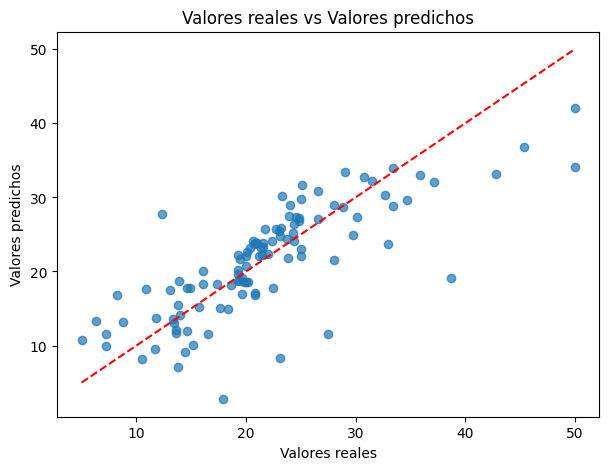

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(y_test, y_pred, alpha=0.7)

# Recta ideal
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],color="red",linestyle="--")

plt.xlabel("Valores reales")
plt.ylabel("Valores predichos")
plt.title("Valores reales vs Valores predichos")

plt.show()

Se observa que la mayoría de las predicciones se distribuyen alrededor de la recta ideal, indicando una capacidad predictiva adecuada. Si bien existe cierta dispersión, especialmente para algunos valores extremos, el modelo logra capturar la tendencia general de los datos, en concordancia con las métricas de desempeño obtenidas.

#### Residuos vs Predichos

Este gráfico permite evaluar visualmente si los errores del modelo presentan un comportamiento aleatorio. En una regresión lineal se espera que los residuos se distribuyan alrededor de cero, sin patrones visibles y con una dispersión aproximadamente constante. La presencia de curvaturas, cambios en la dispersión o agrupamientos podría indicar incumplimiento de los supuestos del modelo o relaciones no lineales entre las variables.

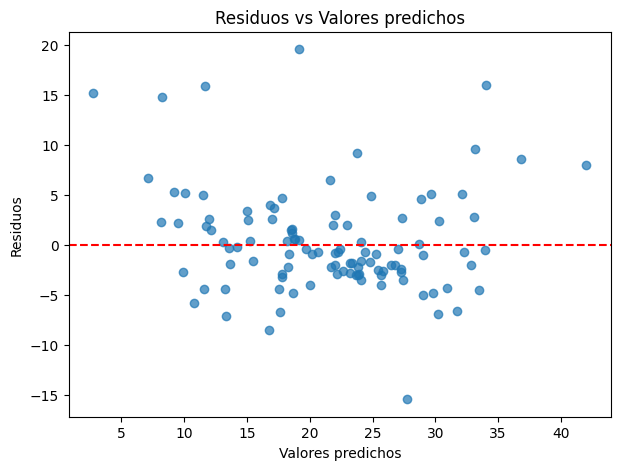

In [ ]:
# Residuos
residuos = y_test - y_pred
plt.figure(figsize=(7,5))

plt.scatter(y_pred,residuos,alpha=0.7)
plt.axhline(y=0,color="red",linestyle="--")

plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos vs Valores predichos")
plt.show()

El gráfico de residuos versus valores predichos muestra una distribución aproximadamente aleatoria alrededor de cero, sin patrones sistemáticos que indiquen una violación evidente del supuesto de linealidad. Asimismo, la dispersión de los residuos se mantiene relativamente constante a lo largo del rango de predicciones, aunque se observan algunos valores atípicos aislados. En conjunto, el análisis visual respalda que el modelo lineal constituye una aproximación razonable para el problema estudiado.

#### Algoritmos de gradiente descendente:

Para complementar la comparación con las implementaciones disponibles en scikit-learn, se incluyen implementaciones propias de los algoritmos de descenso por gradiente.

In [ ]:
def gradient_descent(X_train, y_train, X_val, y_val, lr=0.01, epochs=100):
    n = X_train.shape[0]
    m = X_train.shape[1]
    o = X_val.shape[0]

    # Poner columna de unos a las matrices X
    X_train = np.hstack((np.ones((n, 1)), X_train))
    X_val = np.hstack((np.ones((o, 1)), X_val))

    # Inicializar pesos aleatorios
    W = np.random.randn(m+1).reshape(m+1, 1)

    train_errors = []
    test_errors = []

    for _ in range(epochs):
        prediction_train = np.matmul(X_train, W)
        error_train = y_train - prediction_train
        train_mse = np.mean(error_train ** 2)
        train_errors.append(train_mse)

        prediction_test = np.matmul(X_val, W)
        error_test = y_val - prediction_test
        test_mse = np.mean(error_test ** 2)
        test_errors.append(test_mse)

        grad_sum = np.sum(error_train * X_train, axis=0)
        grad_mul = -2/n * grad_sum
        gradient = np.transpose(grad_mul).reshape(-1, 1)

        W = W - (lr * gradient)

    plt.figure(figsize=(10, 5))
    plt.plot(train_errors, label='Error de entrenamiento')
    plt.plot(test_errors, label='Error de validación')
    plt.xlabel('Época')
    plt.ylabel('Error cuadrático medio')
    plt.legend()
    plt.title('Error de entrenamiento y validación vs iteraciones (GD)')
    plt.show()

    return W


def stochastic_gradient_descent(X_train, y_train, X_test, y_test, lr=0.01, epochs=100):
    n = X_train.shape[0]
    m = X_train.shape[1]

    X_train = np.hstack((np.ones((n, 1)), X_train))
    X_test = np.hstack((np.ones((X_test.shape[0], 1)), X_test))

    W = np.random.randn(m + 1).reshape(-1, 1)

    train_errors = []
    test_errors = []

    for i in range(epochs):
        permutation = np.random.permutation(n)
        X_train = X_train[permutation]
        y_train = y_train[permutation]

        for j in range(n):
            x_sample = X_train[j]
            y_sample = y_train[j][0]

            prediction = np.matmul(x_sample, W)
            error = y_sample - prediction
            train_mse = error ** 2
            train_errors.append(train_mse)

            prediction_test = np.matmul(X_test, W)
            error_test = y_test - prediction_test
            test_mse = np.mean(error_test ** 2)
            test_errors.append(test_mse)

            gradient = -2 * error * x_sample.T.reshape(-1, 1)
            W = W - (lr * gradient)

    plt.figure(figsize=(10, 5))
    plt.plot(train_errors, label='Error de entrenamiento')
    plt.plot(test_errors, label='Error de validación')
    plt.xlabel('Iteración')
    plt.ylabel('Error cuadrático medio')
    plt.legend()
    plt.title('Error de entrenamiento y validación vs iteraciones (SGD)')
    plt.show()

    return W


def mini_batch_gradient_descent(X_train, y_train, X_test, y_test, lr=0.01, epochs=100, batch_size=16):
    n = X_train.shape[0]
    m = X_train.shape[1]

    X_train = np.hstack((np.ones((n, 1)), X_train))
    X_test = np.hstack((np.ones((X_test.shape[0], 1)), X_test))

    W = np.random.randn(m + 1).reshape(-1, 1)

    train_errors = []
    test_errors = []

    for i in range(epochs):
        permutation = np.random.permutation(n)
        X_train = X_train[permutation]
        y_train = y_train[permutation]

        for j in range(0, n, batch_size):
            x_batch = X_train[j:j+batch_size, :]
            y_batch = y_train[j:j+batch_size].reshape(-1, 1)

            prediction = np.matmul(x_batch, W)
            error = y_batch - prediction
            train_mse = np.mean(error ** 2)
            train_errors.append(train_mse)

            gradient = -2 * np.matmul(x_batch.T, error) / batch_size
            W = W - (lr * gradient)

            prediction_test = np.matmul(X_test, W)
            error_test = y_test - prediction_test
            test_mse = np.mean(error_test ** 2)
            test_errors.append(test_mse)

    plt.figure(figsize=(10, 5))
    plt.plot(train_errors, label='Error de entrenamiento')
    plt.plot(test_errors, label='Error de validación')
    plt.xlabel('Iteración')
    plt.ylabel('Error cuadrático medio')
    plt.legend()
    plt.title('Error de entrenamiento y validación vs iteraciones (Mini-Batch GD)')
    plt.show()

    return W

#### Implementacion de los algoritmos GD

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error

In [ ]:
# Set de validación separada desde el train
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=123)

# Reshape necesario para usar las variables objetivo con el código dado por la cátedra
y_tr_gd   = y_tr.values.reshape(-1, 1)
y_val_gd  = y_val.values.reshape(-1, 1)
y_test_gd = y_test.values.reshape(-1, 1)


In [ ]:
print(f"Dimensiones de X_tr:   {X_tr.shape}, y_tr:   {y_tr.shape}")
print(f"Dimensiones de X_val:  {X_val.shape}, y_val:  {y_val.shape}")
print(f"Dimensiones de X_test: {X_test.shape}, y_test: {y_test.shape}")

Dimensiones de X_tr:   (342, 13), y_tr:   (342,)
Dimensiones de X_val:  (86, 13), y_val:  (86,)
Dimensiones de X_test: (107, 13), y_test: (107,)


In [ ]:
pipeline.fit(X_tr, y_tr)

print('R² en validación:', round(r2_score(y_val, pipeline.predict(X_val)),3))

R² en validación: 0.564


Teniendo en cuenta que el R² con CV dio 0.541 y en validación, 0.564, se puede afirmar que la brecha es muy chica y que sería una señal de underfitting, como se supuso antes. Se procede a moniterear si mejora con las regulaciones y el gradiente.

#### Comportamiento con Gradiente Descendiente

In [ ]:
prep = pipeline.named_steps['preprocesador'] # se asegura la imputacion y escalado elegidos anteriormente

X_tr_esc   = prep.fit_transform(X_tr)
X_val_esc  = prep.transform(X_val)
X_test_esc = prep.transform(X_test)


Para aislar el efecto del algoritmo de optimización, inicialmente todos los modelos se entrenan utilizando los mismos hiperparámetros.

Entrenamiento con Batch GD


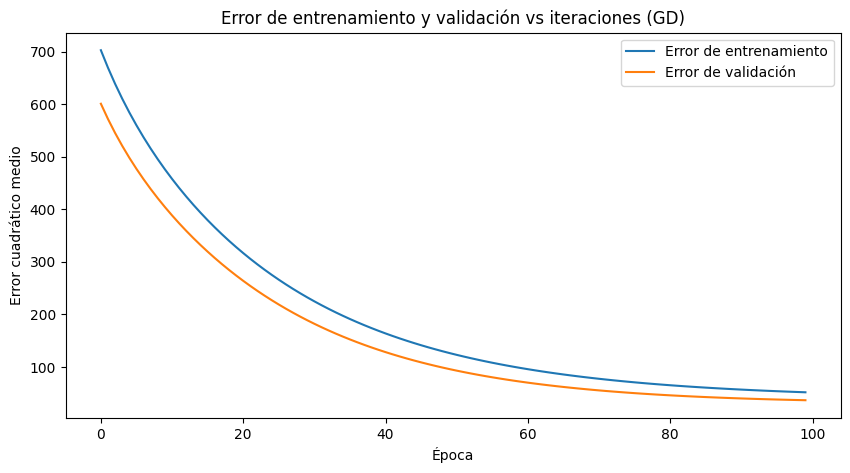

Entrenamiento con SGD


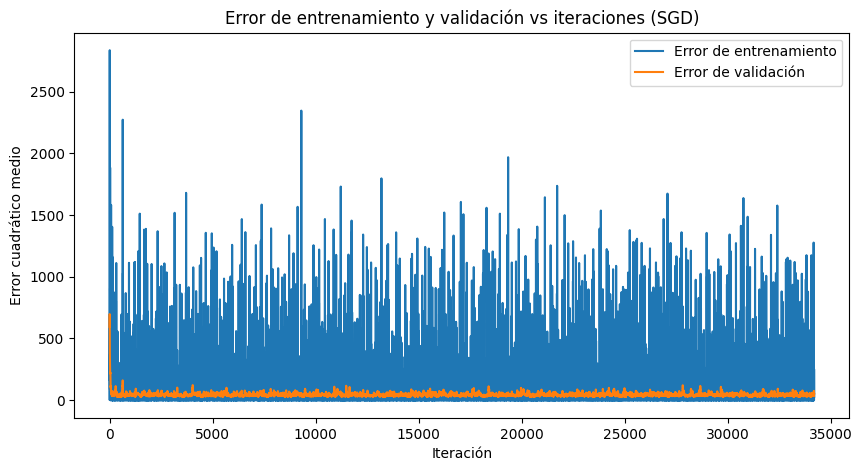

Entrenamiento con Mini-Batch GD


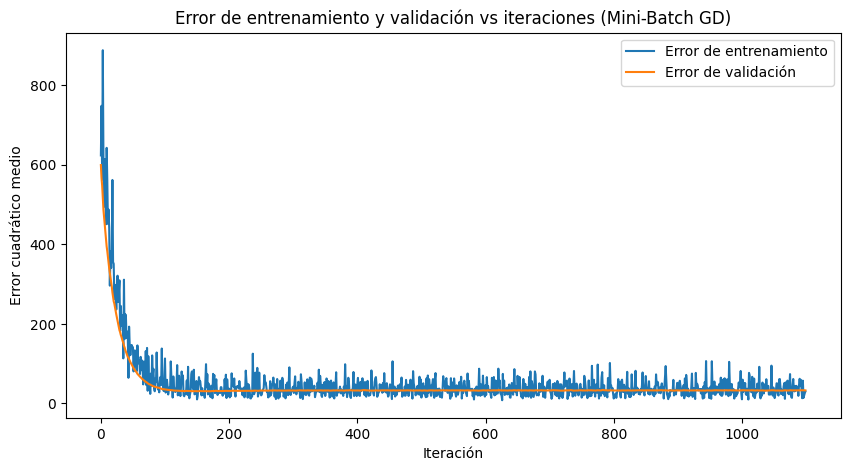

In [ ]:
np.random.seed(123)

# Batch Gradient Descent
print("Entrenamiento con Batch GD")
W_gd   = gradient_descent(X_tr_esc, y_tr_gd, X_val_esc, y_val_gd, lr=0.01, epochs=100)

# Stochastic Gradient Descent (SGD)
print("Entrenamiento con SGD")
W_sgd  = stochastic_gradient_descent(X_tr_esc, y_tr_gd, X_val_esc, y_val_gd, lr=0.01, epochs=100)

# Mini-Batch Gradient Descent
print("Entrenamiento con Mini-Batch GD")
W_mbgd = mini_batch_gradient_descent(X_tr_esc, y_tr_gd, X_val_esc, y_val_gd, lr=0.01, epochs=100, batch_size=32)

**Observaciones:**

GD: el error desciende de forma suave y sostenida, sin oscilaciones. Sin embargo, a las 100 épocas la curva todavía sigue bajando (MSE ≈ 52 en entrenamiento y ≈ 37 en validación): con este learning rate, el algoritmo no llega a converger en la cantidad de épocas dada.

SGD: el error de validación cae abruptamente dentro de la primera época, pero luego no se estabiliza: oscila durante todo el entrenamiento con picos frecuentes. El error de entrenamiento graficado corresponde a una única observación por iteración, por lo que es extremadamente ruidoso (valores entre 0 y más de 2.000).

Mini-Batch: comportamiento intermedio. El error de validación desciende de forma suave hasta estabilizarse alrededor de la iteración 100 (≈ 9 épocas), con un MSE cercano a 30-35. El error de entrenamiento por batch mantiene oscilaciones moderadas, pero promediar el gradiente sobre 32 observaciones reduce buena parte del ruido de SGD sin perder velocidad de convergencia.

En conclusión, con los mismos hiperparámetros solo Mini-Batch alcanza una solución estable, con métricas equivalentes a las de LinearRegression (R² ≈ 0.60 en test). GD necesitaría más épocas o un learning rate mayor, y SGD un learning rate menor.

##### Métricas de las gradientes

In [ ]:
# Poner columna de unos a X_test
X_test_b = np.hstack((np.ones((X_test_esc.shape[0], 1)), X_test_esc))

# Predicciones de cada modelo en Test
y_pred_gd   = X_test_b @ W_gd
y_pred_sgd  = X_test_b @ W_sgd
y_pred_mbgd = X_test_b @ W_mbgd

# Evaluación de cada variante en Test
mse_gd   = mean_squared_error(y_test_gd, y_pred_gd)
mse_sgd  = mean_squared_error(y_test_gd, y_pred_sgd)
mse_mbgd = mean_squared_error(y_test_gd, y_pred_mbgd)

r2_gd   = r2_score(y_test_gd, y_pred_gd)
r2_sgd  = r2_score(y_test_gd, y_pred_sgd)
r2_mbgd = r2_score(y_test_gd, y_pred_mbgd)

rmse_gd   = root_mean_squared_error(y_test_gd, y_pred_gd)
rmse_sgd  = root_mean_squared_error(y_test_gd, y_pred_sgd)
rmse_mbgd = root_mean_squared_error(y_test_gd, y_pred_mbgd)

mae_gd    = mean_absolute_error(y_test_gd, y_pred_gd)
mape_gd   = mean_absolute_percentage_error(y_test_gd, y_pred_gd) * 100
mae_sgd   = mean_absolute_error(y_test_gd, y_pred_sgd)
mape_sgd  = mean_absolute_percentage_error(y_test_gd, y_pred_sgd) * 100
mae_mbgd  = mean_absolute_error(y_test_gd, y_pred_mbgd)
mape_mbgd = mean_absolute_percentage_error(y_test_gd, y_pred_mbgd) * 100

results = pd.DataFrame({
    'Algoritmo': ['Batch GD', 'Stochastic GD', 'Mini-Batch GD'],
    'MSE': [mse_gd, mse_sgd, mse_mbgd],
    'RMSE': [rmse_gd, rmse_sgd, rmse_mbgd],
    "R2": [r2_gd, r2_sgd, r2_mbgd],
    "MAE": [mae_gd, mae_sgd, mae_mbgd],
    "MAPE": [mape_gd, mape_sgd, mape_mbgd]
})
print("Métricas sobre test:")
results

Métricas sobre test:


,Algoritmo,MSE,RMSE,R2,MAE,MAPE
0,Batch GD,37.339919,6.110640,0.477130,4.276033,20.859604
1,Stochastic GD,40.636115,6.374646,0.430973,4.944611,30.682014
2,Mini-Batch GD,28.286381,5.318494,0.603906,3.851998,21.419104


In [ ]:
# Métricas sobre train
X_tr_b = np.hstack((np.ones((X_tr_esc.shape[0], 1)), X_tr_esc))

filas = []
for nombre, W in [("Batch GD", W_gd), ("Stochastic GD", W_sgd), ("Mini-Batch GD", W_mbgd)]:
    pred = X_tr_b @ W
    filas.append({
        "Algoritmo": nombre,
        "MSE": mean_squared_error(y_tr_gd, pred),
        "RMSE": root_mean_squared_error(y_tr_gd, pred),
        "R2": r2_score(y_tr_gd, pred),
        "MAE": mean_absolute_error(y_tr_gd, pred),
        "MAPE": mean_absolute_percentage_error(y_tr_gd, pred) * 100
    })

res_train = pd.DataFrame(filas)
print("Métricas sobre train:")
res_train

Métricas sobre train:


,Algoritmo,MSE,RMSE,R2,MAE,MAPE
0,Batch GD,51.276829,7.160784,0.478123,4.522697,19.122451
1,Stochastic GD,51.253844,7.159179,0.478357,5.341768,27.930122
2,Mini-Batch GD,36.769233,6.063764,0.625776,4.002548,18.940820


**Observaciones:**

En los tres métodos el RMSE es menor en test que en entrenamiento, mientras que el R² técnicamente se mantiene igual o disminuye levemente. Esto se debe a que el conjunto de test presenta menor variabilidad en MEDV, lo que reduce los errores absolutos sin implicar un mejor ajuste.

Las diferencias de R² entre ambos conjuntos son leves, por lo que no se observa sobreajuste. Batch GD y SGD presentan un R² bajo (≈ 0.48) ya en entrenamiento, lo que indica subajuste por falta de convergencia con los hiperparámetros utilizados. Mini-Batch, en cambio, alcanza métricas equivalentes a las de LinearRegression (R² ≈ 0.60 en test).


#### Regresion con Ridge

In [ ]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

ridge = Ridge(alpha=1.0)
ridge.fit(X_tr_esc, y_tr)

y_pred_train_ridge = ridge.predict(X_tr_esc)
y_pred_test_ridge  = ridge.predict(X_test_esc)

print("Train RMSE:", round(root_mean_squared_error(y_tr, y_pred_train_ridge), 3))
print("Train R2 Score:", round(r2_score(y_tr, y_pred_train_ridge), 3))
print("Test RMSE:", round(root_mean_squared_error(y_test, y_pred_test_ridge), 3))
print("Test R2 Score:", round(r2_score(y_test, y_pred_test_ridge), 3))

Train RMSE: 6.061
Train R2 Score: 0.626
Test RMSE: 5.324
Test R2 Score: 0.603


#### Regresion con Lasso

In [ ]:
lasso = Lasso(alpha=0.1)
lasso.fit(X_tr_esc, y_tr)

y_pred_train_lasso = lasso.predict(X_tr_esc)
y_pred_test_lasso  = lasso.predict(X_test_esc)

print("Train RMSE:", round(root_mean_squared_error(y_tr, y_pred_train_lasso), 3))
print("Train R2 Score:", round(r2_score(y_tr, y_pred_train_lasso), 3))
print("Test RMSE:", round(root_mean_squared_error(y_test, y_pred_test_lasso), 3))
print("Test R2 Score:", round(r2_score(y_test, y_pred_test_lasso), 3))

Train RMSE: 6.092
Train R2 Score: 0.622
Test RMSE: 5.217
Test R2 Score: 0.619


#### Regresión con ElasticNet

In [ ]:
elastic = ElasticNet(alpha=0.1, l1_ratio=0.5)
elastic.fit(X_tr_esc, y_tr)

y_pred_train_elastic = elastic.predict(X_tr_esc)
y_pred_test_elastic  = elastic.predict(X_test_esc)

print("Train RMSE:", round(root_mean_squared_error(y_tr, y_pred_train_elastic), 3))
print("Train R2 Score:", round(r2_score(y_tr, y_pred_train_elastic), 3))
print("Test RMSE:", round(root_mean_squared_error(y_test, y_pred_test_elastic), 3))
print("Test R2 Score:", round(r2_score(y_test, y_pred_test_elastic), 3))


Train RMSE: 6.146
Train R2 Score: 0.616
Test RMSE: 5.199
Test R2 Score: 0.621


#### Comparación entre modelos

In [ ]:
lineal = LinearRegression()
lineal.fit(X_tr_esc, y_tr)
y_pred_test_lineal = lineal.predict(X_test_esc)

comparacion = pd.DataFrame({
    "Modelo": ["LinearRegression", "Batch GD", "SGD", "Mini-Batch GD", "Ridge", "Lasso", "Elastic Net"],
    "R² Test": [
        r2_score(y_test, y_pred_test_lineal),
        r2_gd,
        r2_sgd,
        r2_mbgd,
        r2_score(y_test, y_pred_test_ridge),
        r2_score(y_test, y_pred_test_lasso),
        r2_score(y_test, y_pred_test_elastic),
    ],
    "RMSE Test": [
        root_mean_squared_error(y_test, y_pred_test_lineal),
        rmse_gd,
        rmse_sgd,
        rmse_mbgd,
        root_mean_squared_error(y_test, y_pred_test_ridge),
        root_mean_squared_error(y_test, y_pred_test_lasso),
        root_mean_squared_error(y_test, y_pred_test_elastic)
    ]
})

comparacion.sort_values("RMSE Test", ascending=True)

,Modelo,R² Test,RMSE Test
6,Elastic Net,0.621467,5.199258
5,Lasso,0.618927,5.216675
3,Mini-Batch GD,0.603906,5.318494
4,Ridge,0.603011,5.324500
0,LinearRegression,0.601153,5.336944
1,Batch GD,0.477130,6.110640
2,SGD,0.430973,6.374646


**Gráfico de barras para comparación de rendimiento de modelos**

<Figure size 800x600 with 0 Axes>

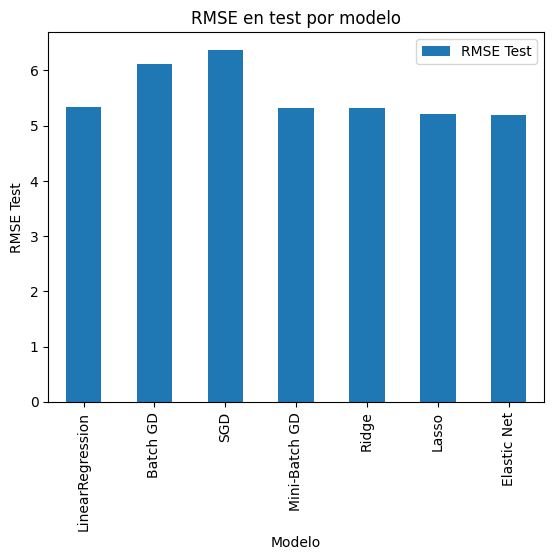

In [ ]:
plt.figure(figsize=(8, 6))
comparacion.plot(
    x="Modelo",
    y="RMSE Test",
    kind="bar",
)
plt.ylabel("RMSE Test")
plt.title("RMSE en test por modelo")
plt.show()

**Observaciones:**

Al ordenar los modelos según su RMSE en test, se distinguen dos grupos bien diferenciados.

El primer grupo está formado por Elastic Net, Lasso, Mini-Batch GD, Ridge y LinearRegression, que presentan un desempeño muy similar.
* Elastic Net obtiene los mejores valores (R² = 0.621 y RMSE = 5.199), seguido de
* Lasso (R² = 0.619 y RMSE = 5.217). A continuación se ubican
* Mini-Batch GD (R² = 0.604 y RMSE = 5.318),
* Ridge (R² = 0.603 y RMSE = 5.324) y
* LinearRegression (R² = 0.601 y RMSE = 5.337), prácticamente equivalentes entre sí.

La diferencia de RMSE entre el mejor y el peor modelo de este grupo es de 0.138, es decir, unos 138 dólares en el precio medio de las viviendas, una diferencia pequeña en términos prácticos.

El segundo grupo lo integran Batch GD y SGD, que quedan claramente por debajo del resto, con R² de 0.477 y 0.431, y RMSE de 6.111 y 6.375, respectivamente. Ambos presentan un R² bajo ya en entrenamiento (0.478), lo que indica que, con los hiperparámetros utilizados, no alcanzaron un ajuste comparable al de los demás modelos.

Al comparar entrenamiento y prueba en los modelos regularizados, se observa que Ridge obtiene el mejor ajuste en entrenamiento (R² = 0.626), pero es el que más pierde en prueba (R² = 0.603). Lasso se mantiene prácticamente igual en ambos conjuntos (0.622 y 0.619), y Elastic Net incluso mejora levemente en prueba (de 0.616 a 0.621). Es decir, los modelos que se ajustan un poco menos a los datos de entrenamiento son los que mejor generalizan, lo cual es el efecto esperado de la regularización. En los tres casos las diferencias entre ambos conjuntos son pequeñas, por lo que no se observa sobreajuste.

En conclusión, tomando como métrica el RMSE en test, elegida porque se expresa en las mismas unidades que MEDV (miles de dólares), Elastic Net es el modelo con mejor desempeño, seguido de Lasso. No obstante, su ventaja sobre Ridge, Mini-Batch GD y LinearRegression es reducida, y todos los modelos del primer grupo explican alrededor del 60-62% de la varianza del precio. Batch GD y SGD, con la configuración utilizada, no alcanzan ese nivel de desempeño.

#### Optimización a través de variación de hiperparámetros
**de Gradiente Descendiente**

Batch GD y SDG

Batch GD - lr=0.001, epochs=100


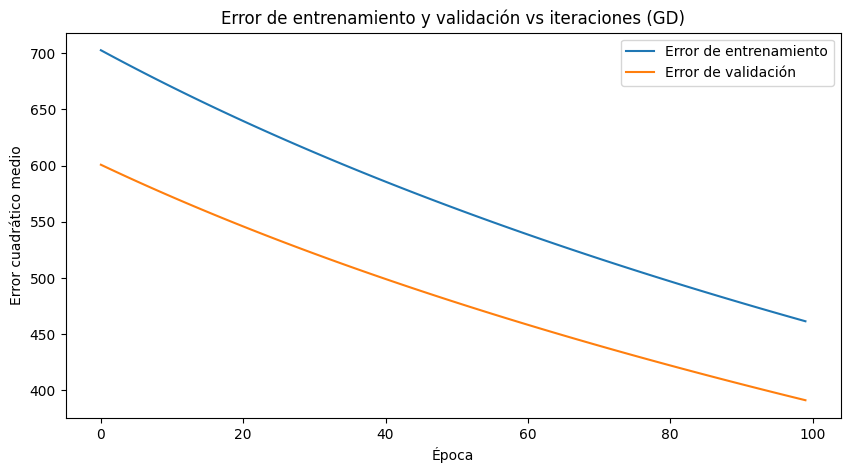

SGD - lr=0.001, epochs=100


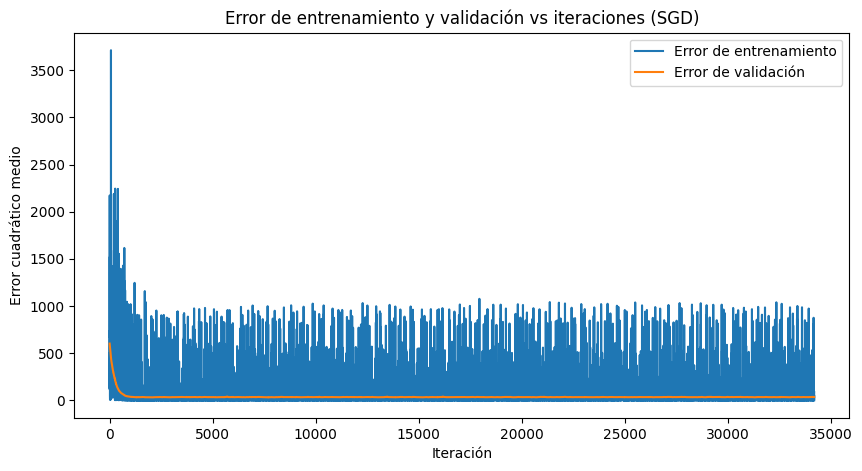

Batch GD - lr=0.001, epochs=300


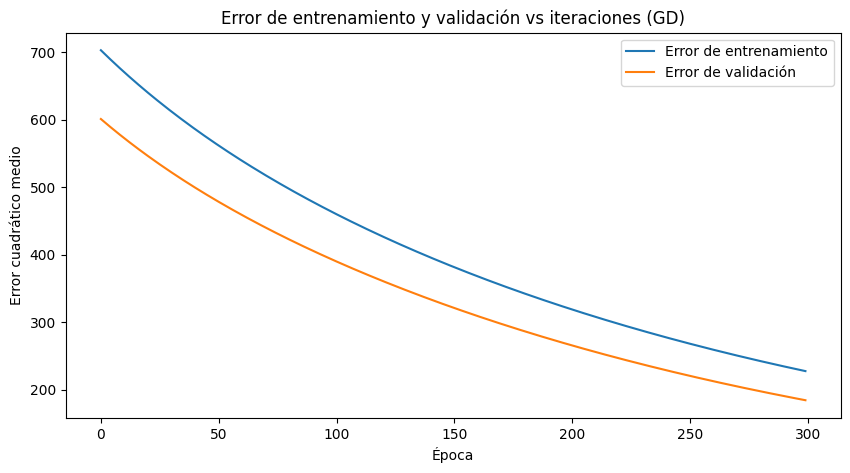

SGD - lr=0.001, epochs=300


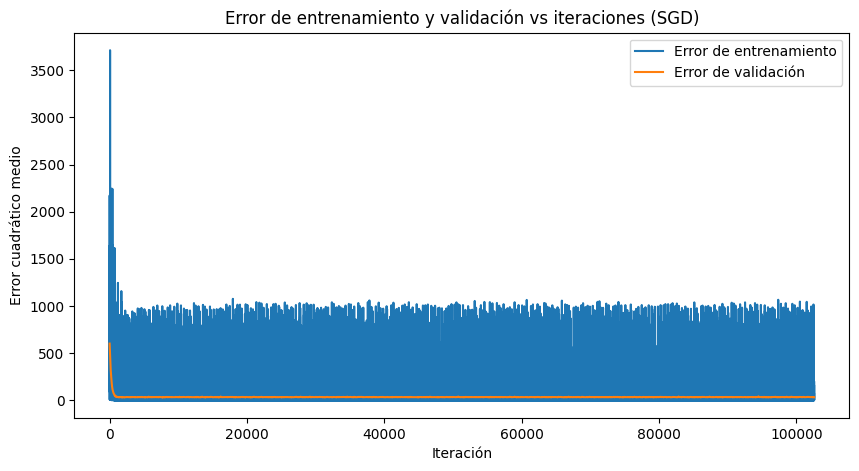

Batch GD - lr=0.001, epochs=500


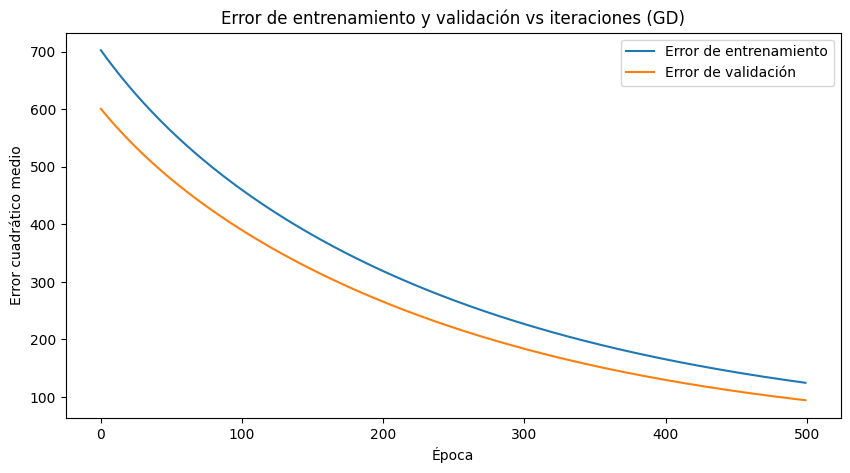

SGD - lr=0.001, epochs=500


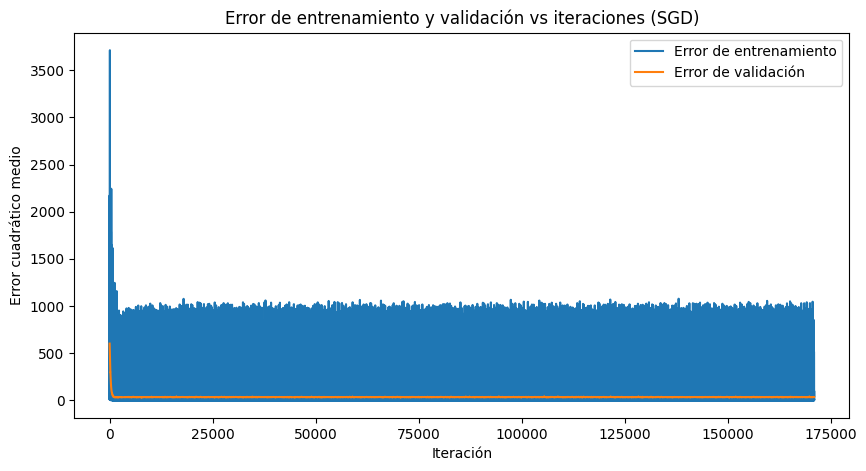

Batch GD - lr=0.005, epochs=100


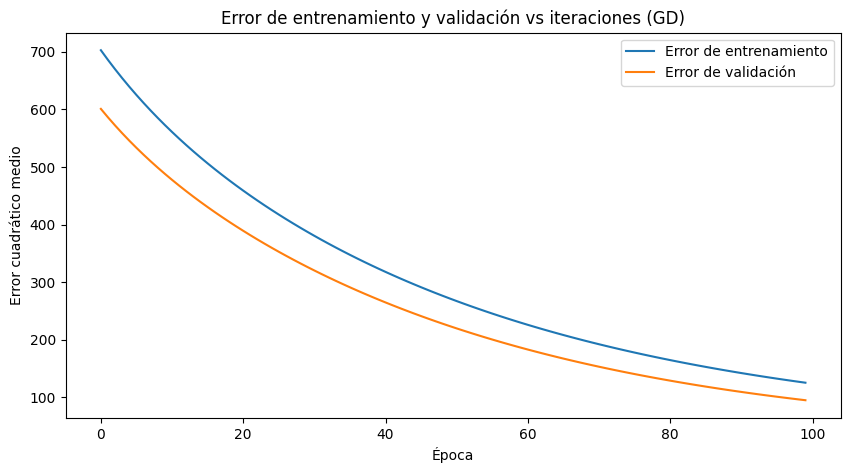

SGD - lr=0.005, epochs=100


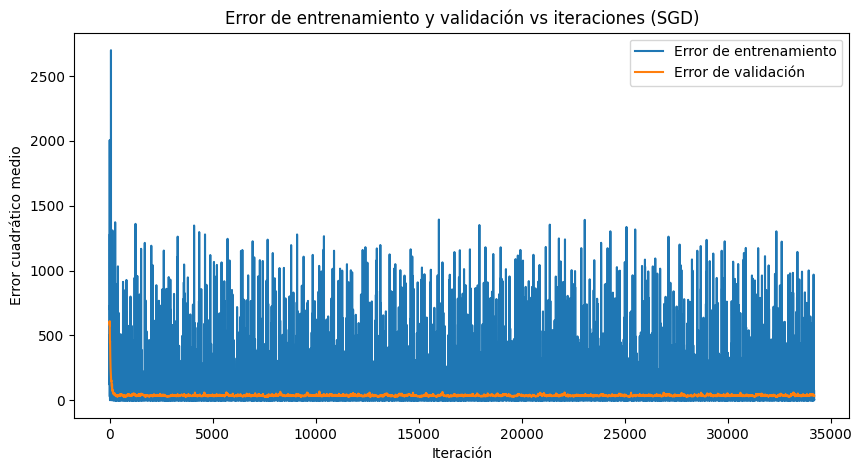

Batch GD - lr=0.005, epochs=300


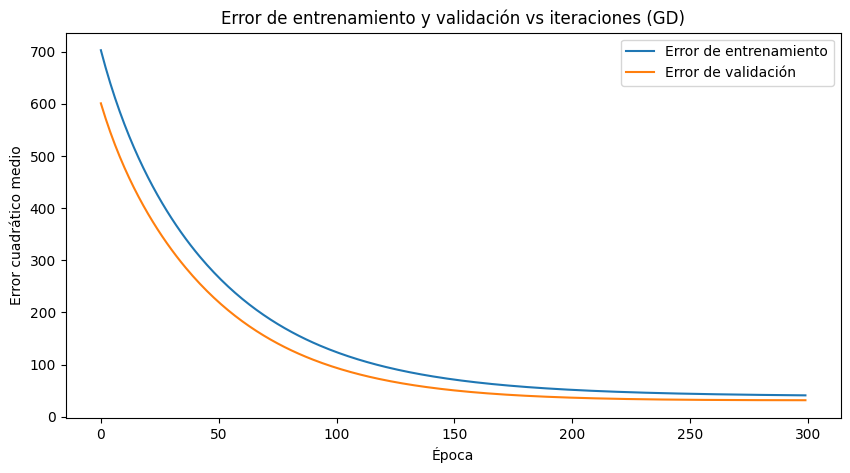

SGD - lr=0.005, epochs=300


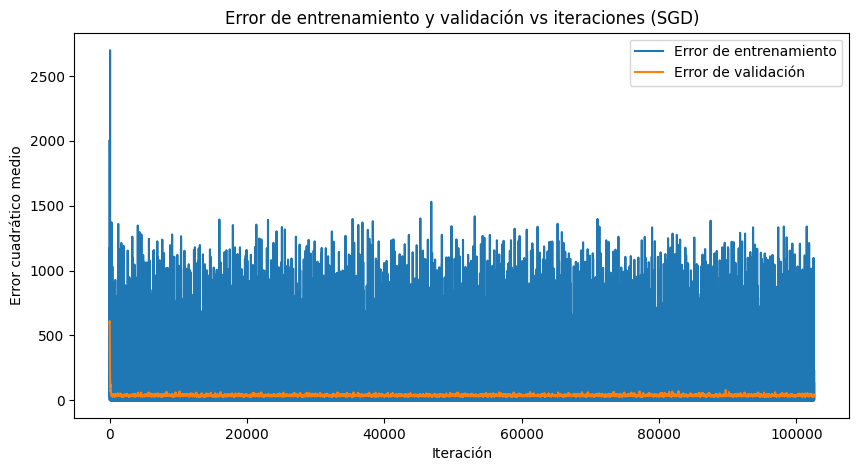

Batch GD - lr=0.005, epochs=500


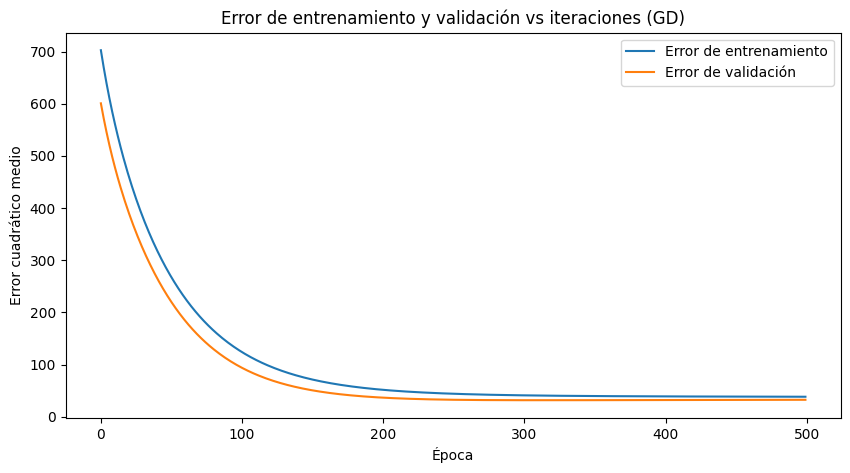

SGD - lr=0.005, epochs=500


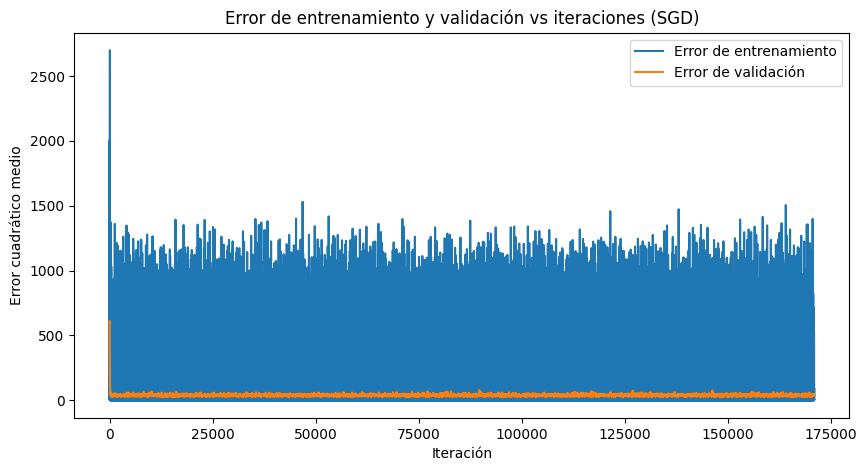

Batch GD - lr=0.01, epochs=100


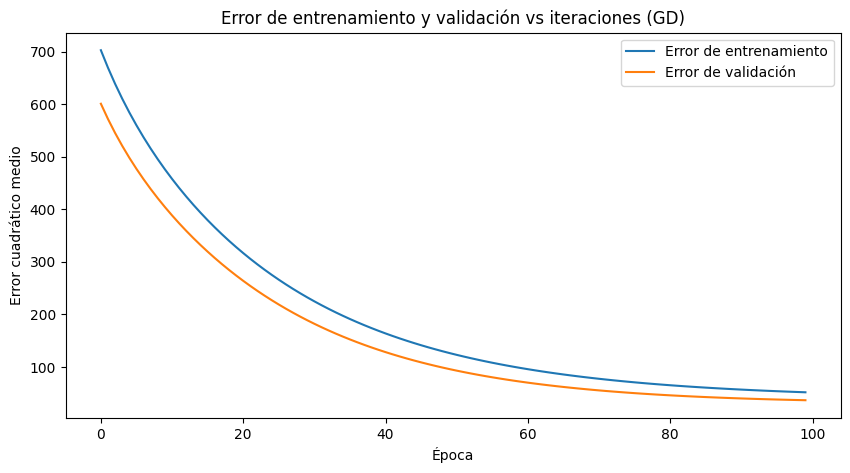

SGD - lr=0.01, epochs=100


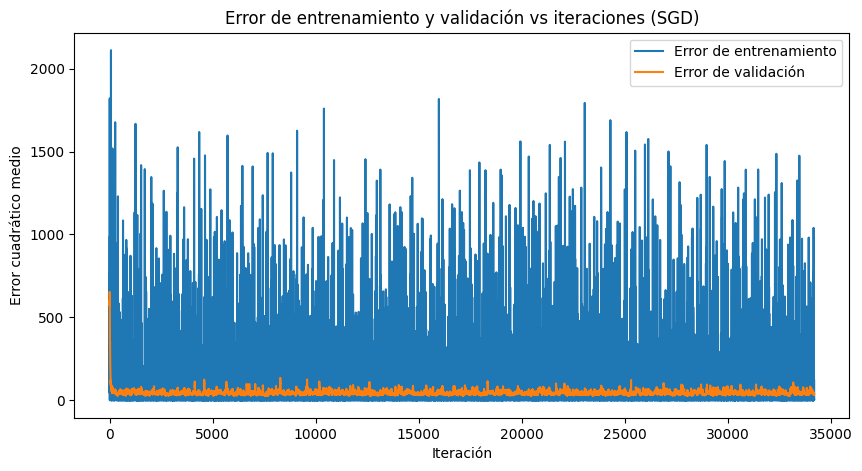

Batch GD - lr=0.01, epochs=300


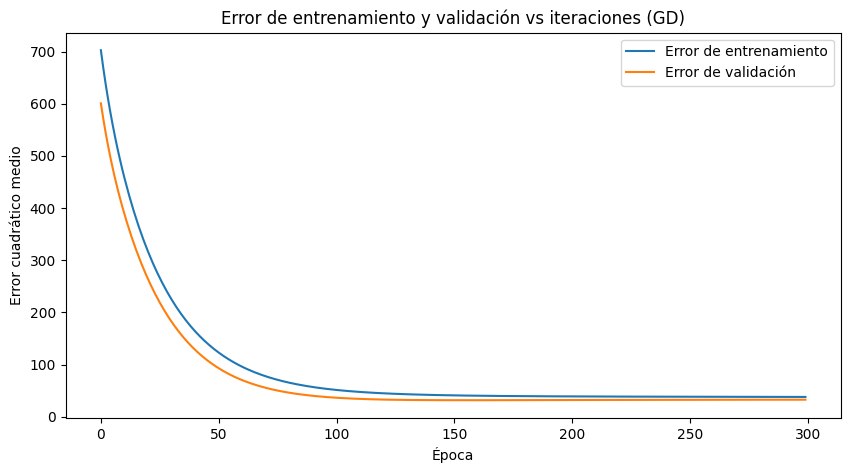

SGD - lr=0.01, epochs=300


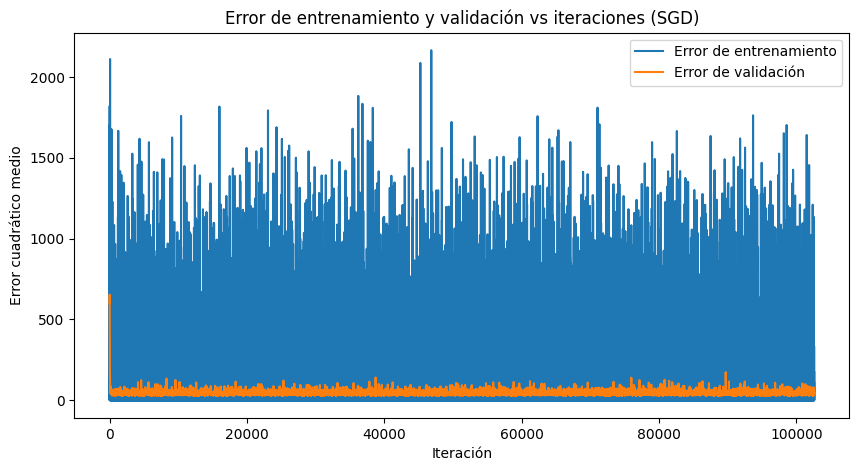

Batch GD - lr=0.01, epochs=500


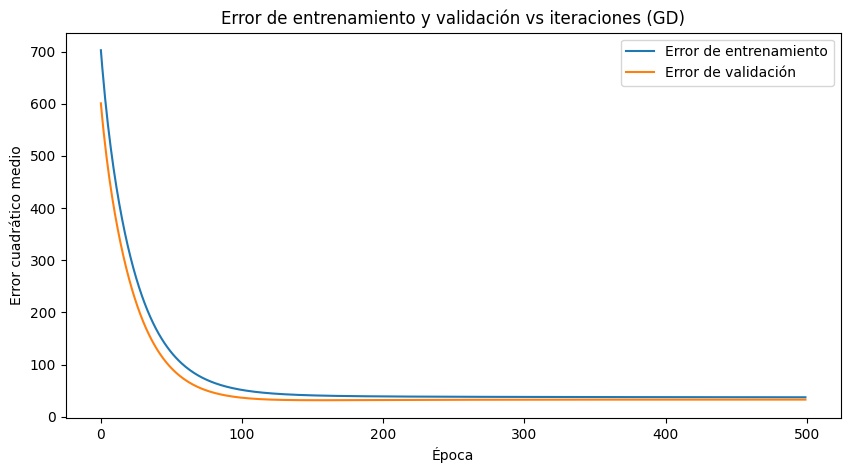

SGD - lr=0.01, epochs=500


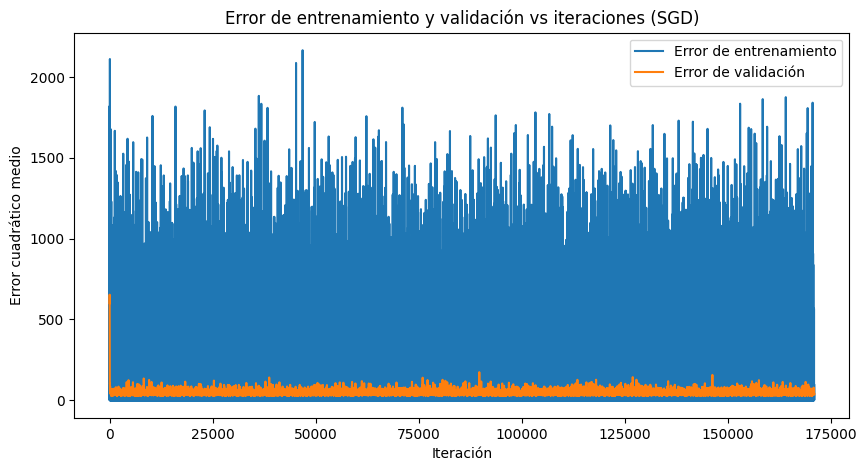

Batch GD - lr=0.02, epochs=100


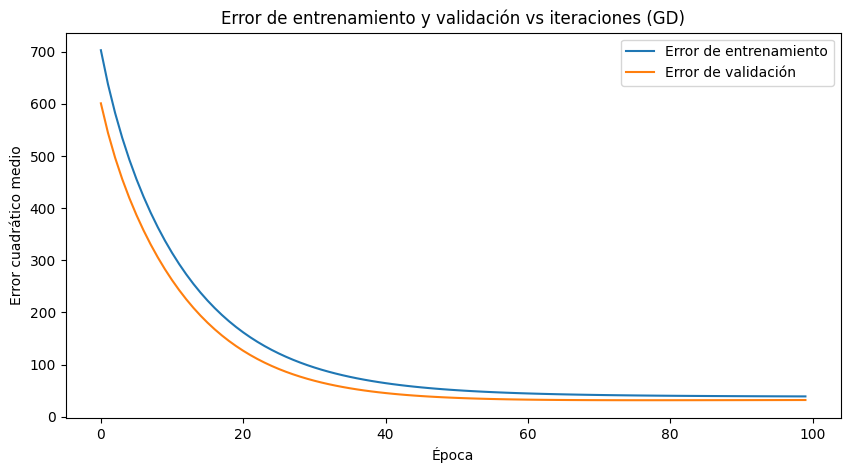

SGD - lr=0.02, epochs=100


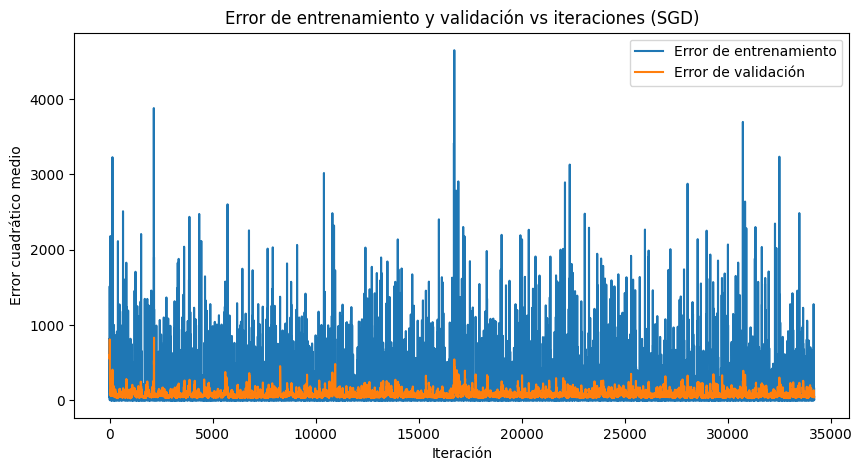

Batch GD - lr=0.02, epochs=300


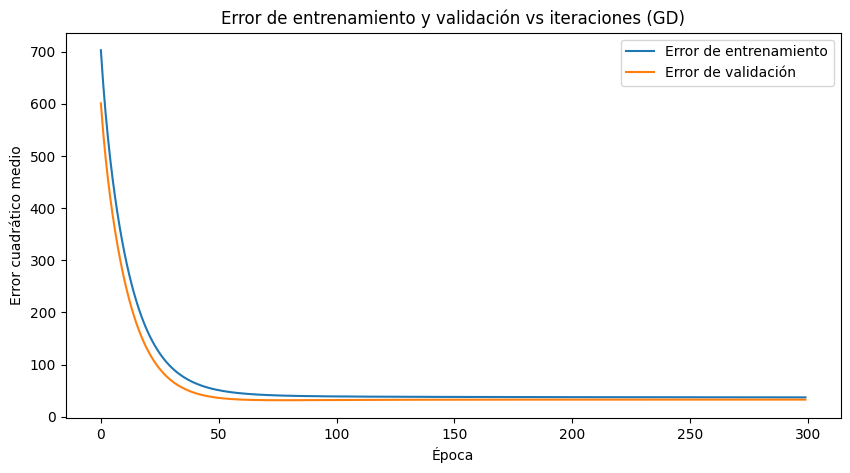

SGD - lr=0.02, epochs=300


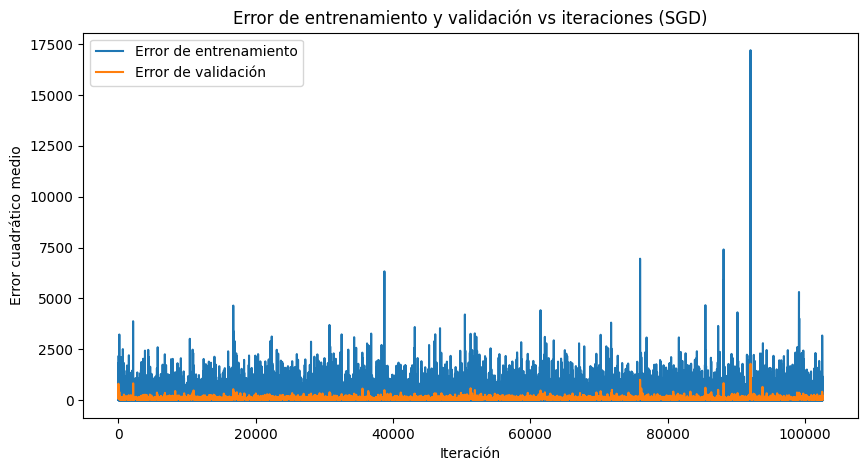

Batch GD - lr=0.02, epochs=500


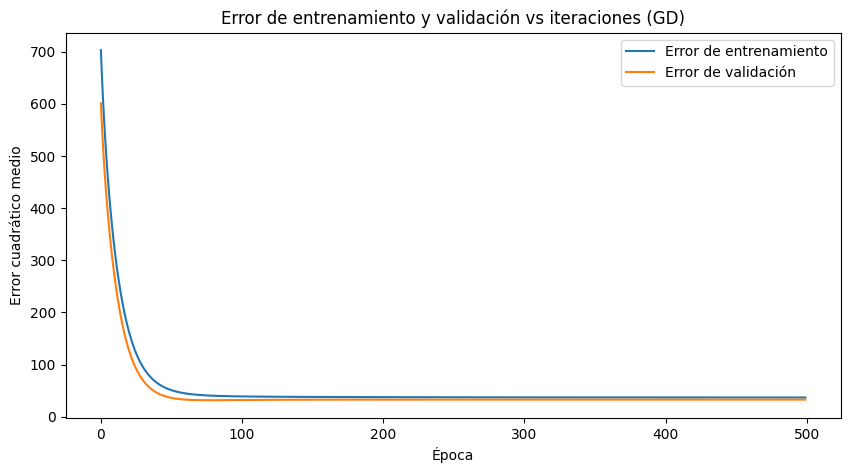

SGD - lr=0.02, epochs=500


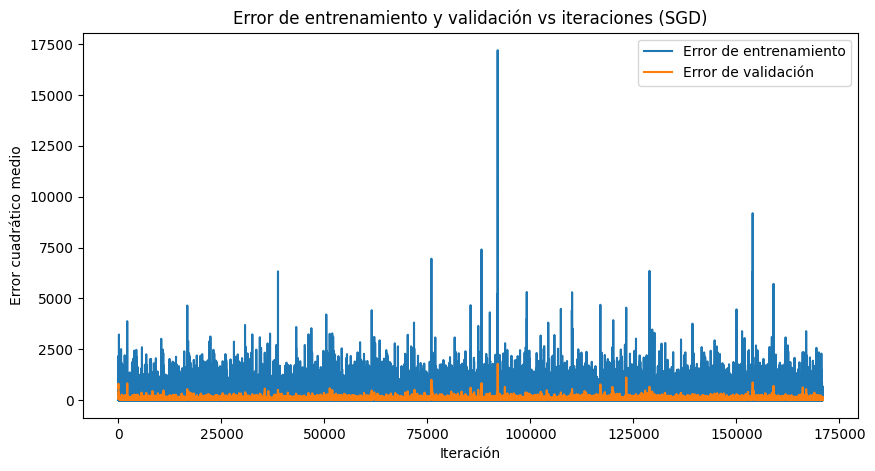

,Algoritmo,Learning Rate,Épocas,RMSE Val,R² Val
0,Batch GD,0.001,100,19.743427,-4.151141
1,SGD,0.001,100,5.813387,0.553402
2,Batch GD,0.001,300,13.556693,-1.428656
3,SGD,0.001,300,5.752065,0.562774
4,Batch GD,0.001,500,9.706059,-0.244928
5,SGD,0.001,500,5.803352,0.554942
6,Batch GD,0.005,100,9.676939,-0.237469
7,SGD,0.005,100,5.901191,0.539809
8,Batch GD,0.005,300,5.624492,0.581953
9,SGD,0.005,300,6.038897,0.518081


In [ ]:
resultados = []

# Columna de unos para evaluar en validación (el test queda reservado para la evaluación final)
X_val_b = np.hstack((np.ones((X_val_esc.shape[0], 1)), X_val_esc))

for lr in [0.001, 0.005, 0.01, 0.02]:
    for ep in [100, 300, 500]:

        print(f"Batch GD - lr={lr}, epochs={ep}")
        np.random.seed(123)  # misma inicialización en cada corrida, para que sea reproducible
        W = gradient_descent(X_tr_esc, y_tr_gd, X_val_esc, y_val_gd, lr=lr, epochs=ep)

        pred_val = X_val_b @ W
        resultados.append({
            "Algoritmo": "Batch GD",
            "Learning Rate": lr,
            "Épocas": ep,
            "RMSE Val": root_mean_squared_error(y_val_gd, pred_val),
            "R² Val": r2_score(y_val_gd, pred_val)
        })

        print(f"SGD - lr={lr}, epochs={ep}")
        np.random.seed(123)
        W = stochastic_gradient_descent(X_tr_esc, y_tr_gd, X_val_esc, y_val_gd, lr=lr, epochs=ep)

        pred_val = X_val_b @ W
        resultados.append({
            "Algoritmo": "SGD",
            "Learning Rate": lr,
            "Épocas": ep,
            "RMSE Val": root_mean_squared_error(y_val_gd, pred_val),
            "R² Val": r2_score(y_val_gd, pred_val)
        })

df_gd = pd.DataFrame(resultados)
display(df_gd)

Los hiperparámetros se seleccionaron según el RMSE sobre el **conjunto de validación**:

Para **Batch Gradient Descent**, la mejor combinación se obtuvo con learning rate igual a 0.005 y 300 épocas (RMSE = 5.624; R² = 0.582). Con LR de 0.001 el algoritmo avanza demasiado lento y no llega a converger en ninguna de las épocas probadas: el R² resulta negativo en todos los casos, es decir, predice peor que la media de MEDV, aunque mejora a medida que aumentan las épocas (de −4.15 a −0.24). Cuando el algoritmo converge, el R² se estabiliza alrededor de 0.566, prácticamente igual al obtenido por LinearRegression en validación (0.564), lo que confirma que Batch GD alcanza la solución de mínimos cuadrados. El mejor resultado, sin embargo, se obtiene poco antes de esa convergencia completa (con lr = 0.005, el R² baja de 0.582 a 0.571 al pasar de 300 a 500 épocas): detener el entrenamiento antes actúa como una regularización implícita. La mejora es pequeña, de alrededor de 0.1 en RMSE.

Para **Stochastic Gradient Descent**, la mejor combinación se obtuvo con LR igual a 0.001 y 300 épocas (RMSE = 5.752; R² = 0.563), un resultado equivalente al de LinearRegression. Con este learning rate el método es estable, con un R² entre 0.553 y 0.563 independientemente de la cantidad de épocas. Al aumentar el learning rate el desempeño empeora y se vuelve irregular: con lr = 0.02 y 300 épocas el R² cae a 0.27, peor que con 100 o 500 épocas.

Mini-Batch GD

Mini-Batch - lr=0.001, batch_size=8


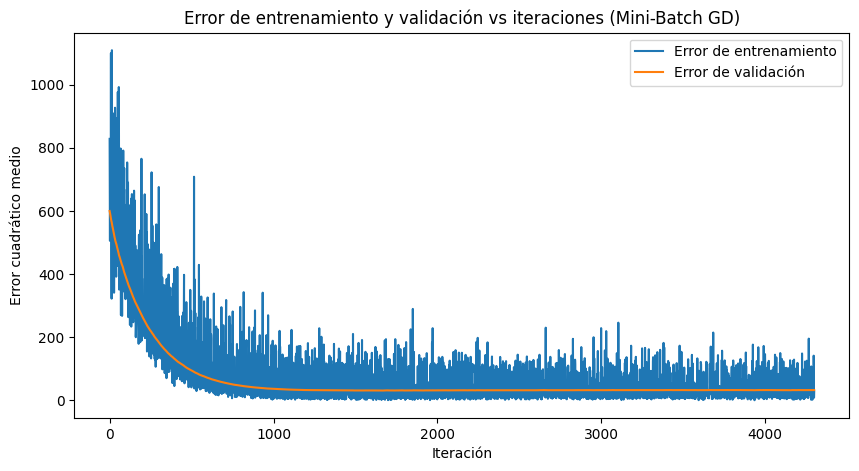

Mini-Batch - lr=0.001, batch_size=32


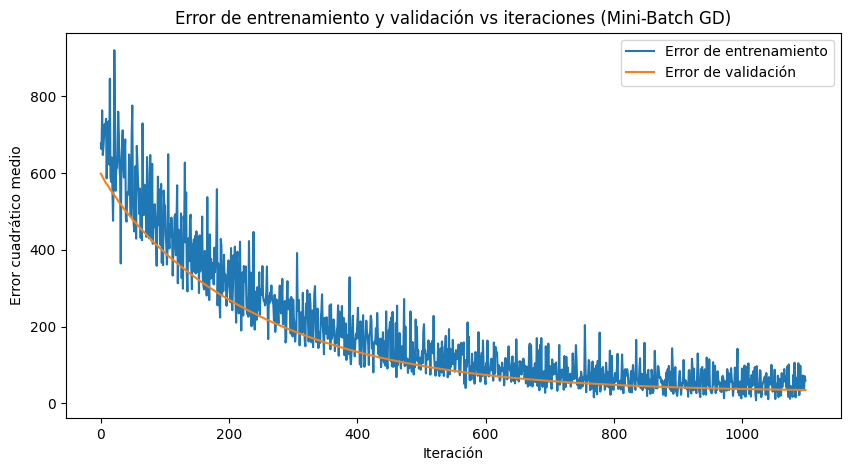

Mini-Batch - lr=0.001, batch_size=128


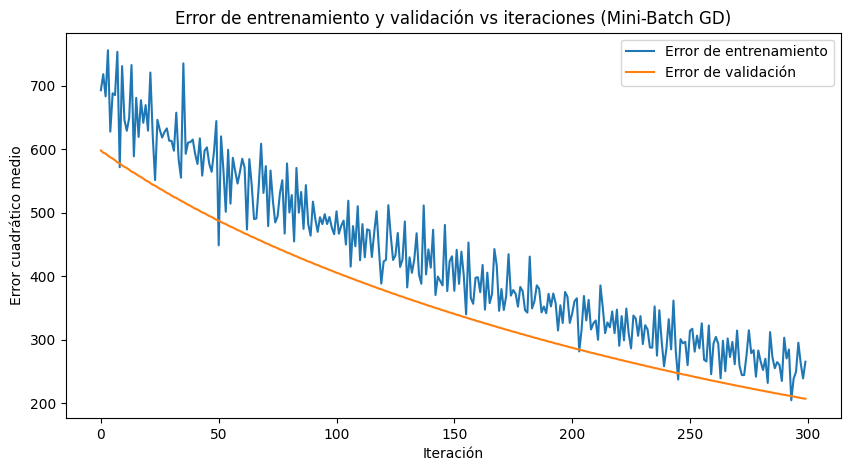

Mini-Batch - lr=0.01, batch_size=8


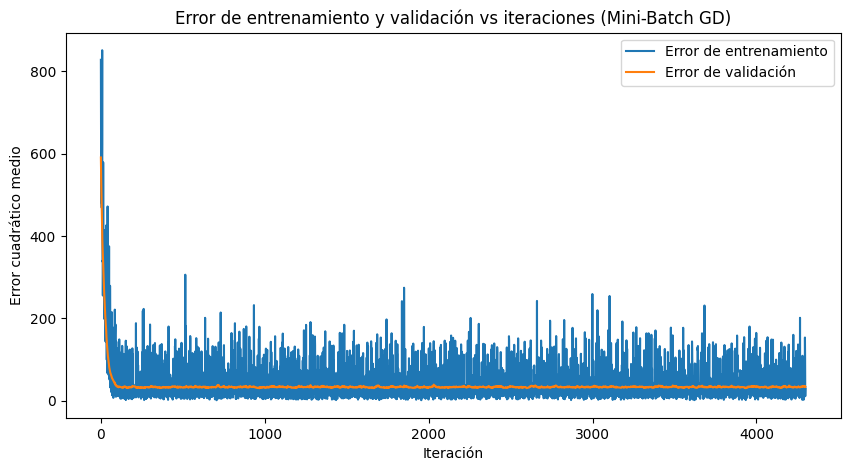

Mini-Batch - lr=0.01, batch_size=32


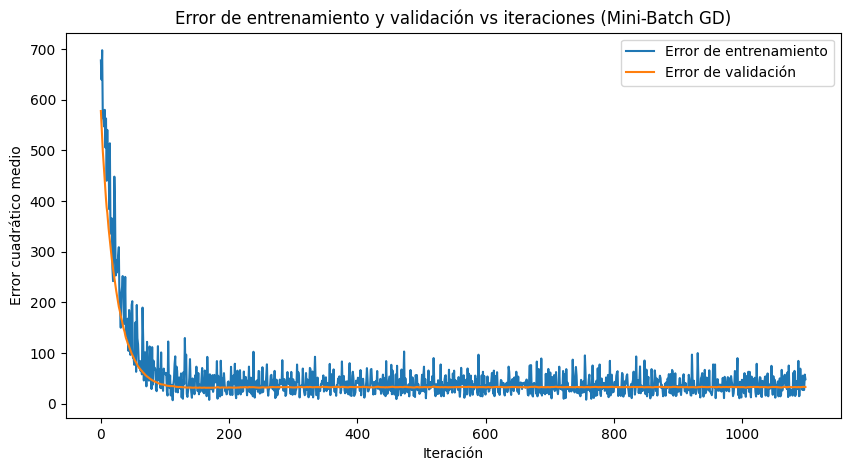

Mini-Batch - lr=0.01, batch_size=128


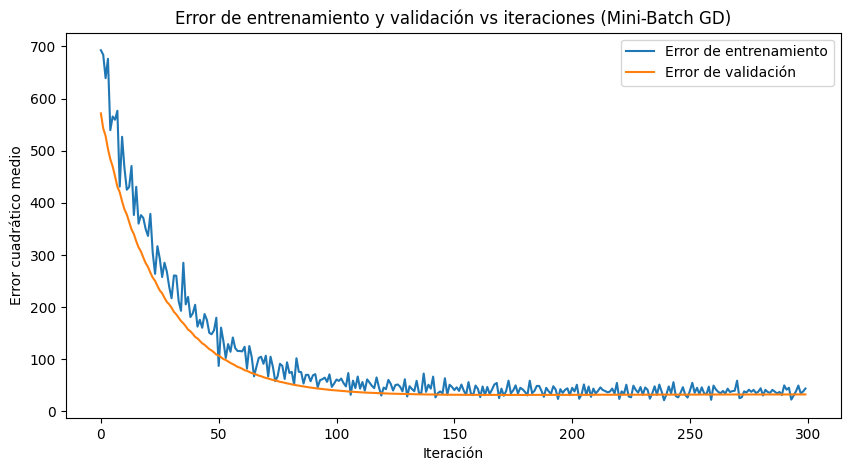

Mini-Batch - lr=0.1, batch_size=8


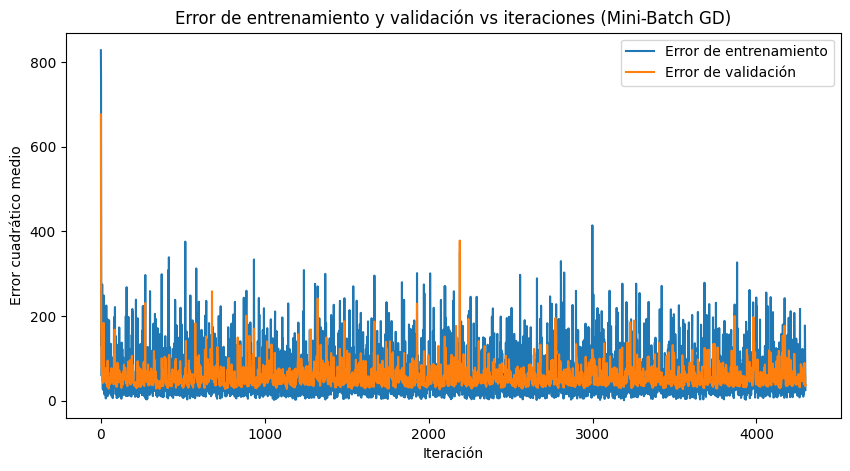

Mini-Batch - lr=0.1, batch_size=32


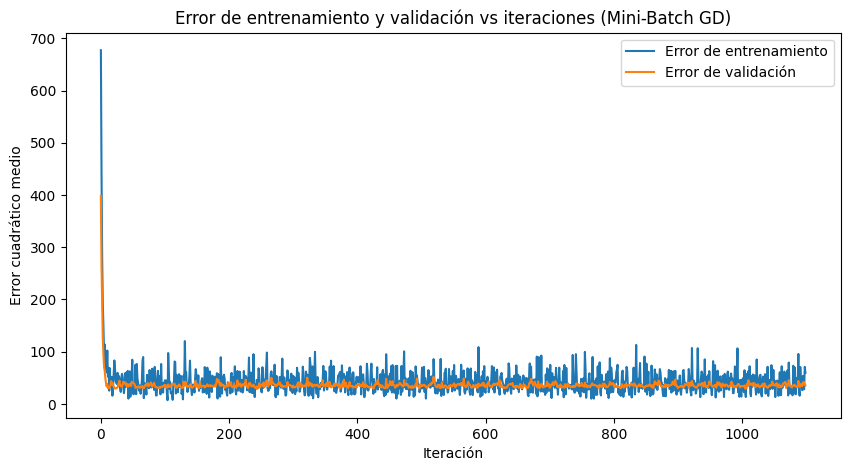

Mini-Batch - lr=0.1, batch_size=128


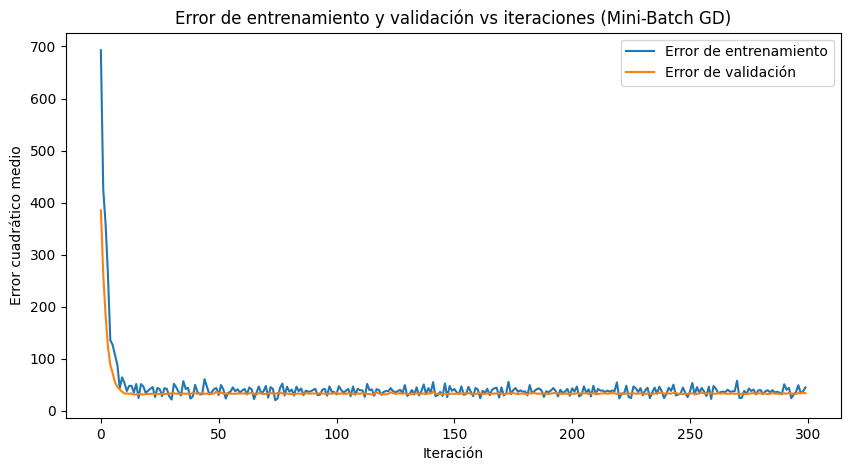

,Learning Rate,Batch Size,RMSE Val,R² Val
0,0.001,8,5.733975,0.565520
1,0.001,32,5.907730,0.538789
2,0.001,128,14.387496,-1.735450
3,0.010,8,5.824793,0.551648
4,0.010,32,5.749430,0.563175
5,0.010,128,5.706497,0.569674
6,0.100,8,6.102583,0.507863
7,0.100,32,5.945747,0.532834
8,0.100,128,5.810485,0.553848


In [ ]:
resultados = []

# Columna de unos para evaluar en validación (el test queda reservado para la comparación final)
X_val_b = np.hstack((np.ones((X_val_esc.shape[0], 1)), X_val_esc))

for lr in [0.001, 0.01, 0.1]:
    for bs in [8, 32, 128]:

        print(f"Mini-Batch - lr={lr}, batch_size={bs}")
        np.random.seed(123)  # misma inicialización y orden de batches en cada corrida
        W = mini_batch_gradient_descent(
            X_tr_esc,
            y_tr_gd,
            X_val_esc,
            y_val_gd,
            lr=lr,
            epochs=100,
            batch_size=bs
        )

        pred_val = X_val_b @ W

        resultados.append({
            "Learning Rate": lr,
            "Batch Size": bs,
            "RMSE Val": root_mean_squared_error(y_val_gd, pred_val),
            "R² Val": r2_score(y_val_gd, pred_val)
        })

df_mbgd = pd.DataFrame(resultados)

display(df_mbgd)

Para **Mini-Batch**, la mejor combinación se obtuvo con learning rate igual a 0.01 y batch size de 128 (RMSE = 5.706; R² = 0.570 en validación), un resultado prácticamente equivalente al de LinearRegression (R² = 0.564).

Los resultados muestran que el learning rate y el tamaño del batch interactúan entre sí. Con un learning rate bajo (0.001) conviene un batch pequeño: con batch de 8 se realizan unas 43 actualizaciones por época y el modelo alcanza un R² de 0.566, mientras que con batch de 128 se realizan solo 3 por época, y con un paso tan chico el algoritmo no llega a converger en 100 épocas (R² = −1.74). Con un learning rate alto (0.1) ocurre lo contrario: los batches pequeños producen un gradiente ruidoso que el paso grande amplifica (R² = 0.508 con batch de 8), mientras que los batches grandes promedian más observaciones y estabilizan el recorrido (R² = 0.554 con batch de 128). Con learning rate de 0.01 las tres configuraciones convergen, con R² entre 0.55 y 0.57.

En la comparación entre las tres variantes, con sus mejores hiperparámetros,
* Batch GD obtuvo el menor error en validación (RMSE = 5.624; R² = 0.582), seguido por
* Mini-Batch GD (RMSE = 5.706; R² = 0.570) y
* SGD (RMSE = 5.752; R² = 0.563).

Las diferencias son pequeñas, y los tres métodos alcanzan resultados muy cercanos al de LinearRegression (R² = 0.564), lo que confirma que todos minimizan la misma función de pérdida y convergen a soluciones similares cuando los hiperparámetros son adecuados.

**de Ridge, Lasso y ElasticNet**

In [ ]:
from sklearn.model_selection import GridSearchCV


Ridge
Mejores parámetros: {'model__alpha': np.float64(17.78279410038923)}
RMSE CV   : 6.4941
RMSE Test : 5.1967
R² Test    : 0.6218

Lasso
Mejores parámetros: {'model__alpha': np.float64(0.1)}
RMSE CV   : 6.4711
RMSE Test : 5.1700
R² Test    : 0.6257

Elastic Net
Mejores parámetros: {'model__alpha': np.float64(0.1), 'model__l1_ratio': 0.8}
RMSE CV   : 6.4705
RMSE Test : 5.1683
R² Test    : 0.6260


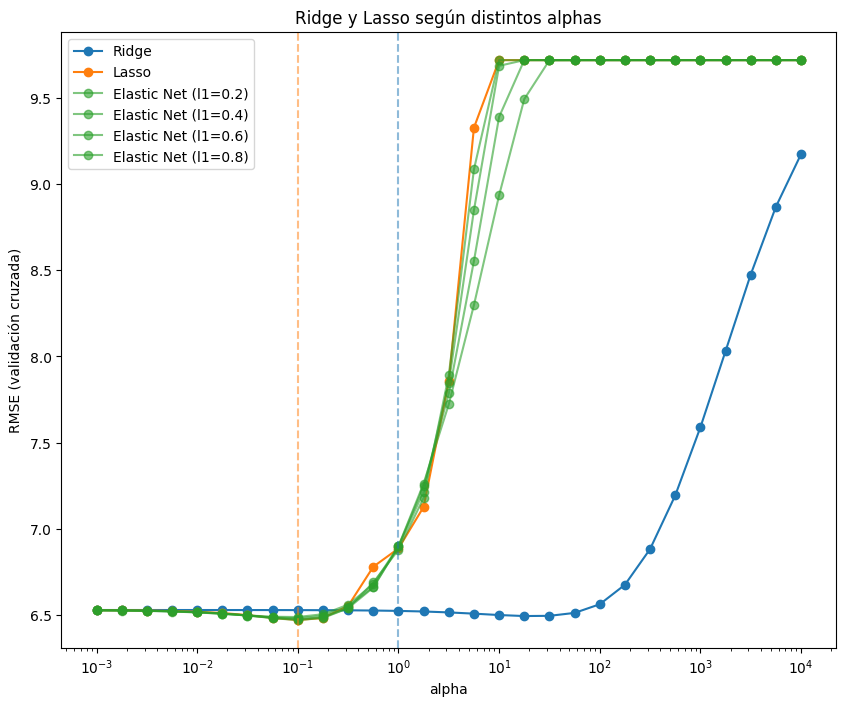

In [ ]:
alphas = np.logspace(-3, 4, 29)


modelos = [
    ("Ridge", Ridge(), {"model__alpha": alphas}),
    ("Lasso", Lasso(max_iter=10000, random_state=42), {"model__alpha": alphas}),
    ("Elastic Net",ElasticNet(max_iter=10000),{"model__alpha": alphas,"model__l1_ratio": [0.2, 0.4, 0.6, 0.8]})
]

plt.figure(figsize=(10, 8))

for nombre, modelo, parametros in modelos:
    pipe_reg = Pipeline([('preprocesador', preprocesador), ('model', modelo)])
    grid = GridSearchCV(pipe_reg, parametros, cv=kf,
                        scoring="neg_root_mean_squared_error")
    grid.fit(X_train, y_train)
    mejor_modelo = grid.best_estimator_
    pred_test = mejor_modelo.predict(X_test)
    rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))
    r2_test = r2_score(y_test, pred_test)

    print(f"\n{nombre}")
    print("Mejores parámetros:", grid.best_params_)
    print(f"RMSE CV   : {-grid.best_score_:.4f}")
    print(f"RMSE Test : {rmse_test:.4f}")
    print(f"R² Test    : {r2_test:.4f}")

    resultados = pd.DataFrame(grid.cv_results_)

    if nombre == "Elastic Net":
        l1_ratios = sorted(resultados["param_model__l1_ratio"].unique())
        for l1 in l1_ratios:
          datos = resultados[resultados["param_model__l1_ratio"] == l1]
          plt.plot(
            datos["param_model__alpha"].astype(float),
            -datos["mean_test_score"],
            marker="o",
            color="C2",
            alpha=0.6,
            label=f"Elastic Net (l1={l1})"
        )
    else:
        plt.plot(alphas, -resultados["mean_test_score"], marker="o", label=nombre)

plt.axvline(1.0, color="C0", linestyle="--", alpha=0.5)  # Ridge actual
plt.axvline(0.1, color="C1", linestyle="--", alpha=0.5)  # Lasso actual
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("RMSE (validación cruzada)")
plt.title("Ridge y Lasso según distintos alphas")
plt.legend()
plt.show()

**Comportamiento general:**

Con alphas muy pequeños (alpha ≤ 0.01), los tres modelos obtienen un RMSE de aproximadamente 6.53, el mismo que LinearRegression (6.529).

**Lasso:** el mejor alpha es 0.1, con un RMSE de validación cruzada de 6.471, y coincide con el valor utilizado inicialmente. A partir de alpha ≈ 0.3 el error aumenta abruptamente, y desde alpha = 10 se estabiliza en aproximadamente 9.7. En ese punto la penalización L1 anula todos los coeficientes, y el modelo predice siempre el valor medio de MEDV.

**Ridge:** el mejor alpha es aproximadamente 17.8, con un RMSE de 6.494. La curva es prácticamente plana hasta alpha ≈ 100, por lo que el valor utilizado inicialmente (alpha = 1) da un resultado muy similar. A partir de ese punto el error crece de forma gradual, sin llegar al nivel de Lasso.

**Elastic Net:** el mejor desempeño se obtuvo con alpha = 0.1 y l1_ratio = 0.8 (RMSE = 6.4705). Las curvas muestran un comportamiento intermedio entre Ridge y Lasso: cuanto menor es el l1_ratio, más tarde aumenta el error, porque la penalización se parece más a la de Ridge. El l1_ratio óptimo es el más alto de los evaluados, lo que indica que la combinación preferida se acerca a Lasso; de hecho, el resultado es prácticamente idéntico al de Lasso (6.4711).

**Conclusión:** los tres modelos regularizados alcanzan un RMSE mínimo entre 6.47 y 6.49, frente a 6.53 de LinearRegression. La mejora es muy pequeña (alrededor de 0.06) en comparación con la variabilidad entre folds (± 0.74), por lo que la regularización no aporta una mejora significativa con este conjunto de datos. Esto es coherente con que el modelo lineal no presentaba sobreajuste: la regularización ayuda a controlar la varianza, pero no resuelve el subajuste.

#### Comparación final de modelos

Para comparar los modelos se utilizan dos métricas complementarias:

- **RMSE (raíz del error cuadrático medio):** se expresa en las mismas unidades que MEDV (miles de dólares), por lo que indica directamente cuánto se equivoca el modelo en promedio. Al elevar los errores al cuadrado antes de promediarlos, penaliza más los errores grandes.
- **R² (coeficiente de determinación):** indica qué proporción de la variabilidad de MEDV explica el modelo. Al no depender de las unidades, permite evaluar la calidad del ajuste en términos relativos.

In [ ]:
from unittest.mock import patch
#patch evita que las funciones de la cátedra muestren sus gráficos, que ya se analizaron antes


with patch("matplotlib.pyplot.show"):
    np.random.seed(123); W_gd_opt  = gradient_descent(X_tr_esc, y_tr_gd, X_val_esc, y_val_gd, lr=0.005, epochs=300)
    np.random.seed(123); W_sgd_opt = stochastic_gradient_descent(X_tr_esc, y_tr_gd, X_val_esc, y_val_gd, lr=0.001, epochs=300)
    np.random.seed(123); W_mb_opt  = mini_batch_gradient_descent(X_tr_esc, y_tr_gd, X_val_esc, y_val_gd, lr=0.01, epochs=100, batch_size=128)
plt.close("all")

# Modelos con los alphas elegidos por el GridSearch
modelos_sk = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=17.78),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
    "Elastic Net": ElasticNet(alpha=0.1, l1_ratio=0.8, max_iter=10000),
}

filas = []
for nombre, modelo in modelos_sk.items():
    modelo.fit(X_tr_esc, y_tr)
    filas.append((nombre, modelo.predict(X_val_esc), modelo.predict(X_test_esc)))
for nombre, W in [("Batch GD", W_gd_opt), ("SGD", W_sgd_opt), ("Mini-Batch GD", W_mb_opt)]:
    filas.append((nombre, (X_val_b @ W).ravel(), (X_test_b @ W).ravel()))

comparacion_final = pd.DataFrame(
    [[n, root_mean_squared_error(y_val, pv), r2_score(y_val, pv), root_mean_squared_error(y_test, pt), r2_score(y_test, pt)]
     for n, pv, pt in filas],
    columns=["Modelo", "RMSE Val", "R² Val", "RMSE Test", "R² Test"]
).sort_values("RMSE Val")

comparacion_final.round(3)

,Modelo,RMSE Val,R² Val,RMSE Test,R² Test
4,Batch GD,5.624,0.582,5.303,0.606
3,Elastic Net,5.635,0.580,5.207,0.620
1,Ridge,5.645,0.579,5.228,0.617
2,Lasso,5.654,0.578,5.217,0.619
6,Mini-Batch GD,5.706,0.570,5.198,0.622
0,LinearRegression,5.743,0.564,5.337,0.601
5,SGD,5.752,0.563,5.335,0.602


**Resultados de la comparación:**

Según el criterio definido, el modelo con menor RMSE en validación fue Batch GD (RMSE = 5.624; R² = 0.582), seguido muy de cerca por Elastic Net (5.635), Ridge (5.645) y Lasso (5.654). La diferencia entre el mejor y el peor modelo en validación es de apenas 0.13 (unos 130 dólares), con R² entre 0.563 y 0.582.

Sin embargo, en test el orden cambia: Mini-Batch GD obtiene el menor RMSE (5.198; R² = 0.622), mientras que Batch GD pasa al quinto lugar (5.303). Que el ranking se reordene al cambiar de conjunto indica que las diferencias entre los modelos no son significativas.

Por lo tanto, según el criterio definido, el modelo seleccionado es Batch GD. No obstante, su ventaja sobre Elastic Net en validación es mínima (0.011 de RMSE), y proviene de detener el entrenamiento antes de la convergencia completa, por lo que depende de hiperparámetros sensibles como el learning rate, la cantidad de épocas y la inicialización de los pesos.

#### Conclusión

En este proyecto se analizó el problema de predicción del precio de viviendas utilizando distintos enfoques de regresión lineal, evaluando tanto el desempeño predictivo como el impacto de las técnicas de regularización y de los diferentes algoritmos de optimización.

El modelo de regresión lineal base explica alrededor del 60% de la varianza de MEDV, con métricas similares en entrenamiento y prueba: no hay sobreajuste, pero sí un subajuste moderado, ya que una relación lineal no alcanza a capturar toda la estructura de los datos.

Los métodos de gradiente descendente mostraron una fuerte dependencia de sus hiperparámetros: con valores inadecuados no convergieron (Batch GD con learning rate bajo) o se volvieron inestables (SGD con learning rate alto). Una vez ajustados con el conjunto de validación, alcanzaron resultados equivalentes a los de LinearRegression. Su diferencia está en el costo y la estabilidad de la optimización, no en el modelo obtenido.

La regularización no produjo una mejora significativa: el RMSE de validación cruzada pasó de 6.53 en LinearRegression a entre 6.47 y 6.49 en Ridge, Lasso y Elastic Net, una diferencia muy inferior a la variabilidad entre folds (± 0.74). Esto es coherente con la ausencia de sobreajuste: la regularización controla la varianza, pero no corrige el subajuste.

Los resultados obtenidos muestran que todos los modelos evaluados presentaron un desempeño muy similar en términos de RMSE y R².

En conclusión, para este conjunto de datos no se observaron diferencias significativas entre los modelos analizados, lo que indica que la relación entre las variables puede representarse adecuadamente mediante modelos lineales. Si bien Batch GD obtuvo el menor RMSE tras la optimización, la diferencia respecto de los demás modelos fue pequeña, por lo que cualquiera de ellos constituye una alternativa válida para este problema de predicción. Más allá de identificar el modelo con mejor rendimiento, el estudio permitió observar cómo distintas decisiones de modelado (preprocesamiento, regularización e hiperparámetros) afectan el equilibrio entre capacidad predictiva y generalización. Este tipo de análisis resulta útil para comprender no sólo qué modelo obtiene mejores métricas, sino también por qué lo hace.